# S.B.P. — Smart Bus Point
## Estimativa do intervalo de espera no ponto de ônibus

**Global Solution 2026.2 — CitizenTech — Inteligência Artificial & Machine Learning**
FIAP · Engenharia de Software · 3º ano

---

### Ficha da CitizenTech

| Campo | Conteúdo |
| :--- | :--- |
| **Nome da CitizenTech** | S.B.P. — Smart Bus Point |
| **Cidade e bairro** | São Paulo (SP) — rede municipal de ônibus da SPTrans |
| **Cidadão beneficiado** | Passageiro que depende do ônibus e espera no ponto sem saber quanto tempo falta: trabalhador, estudante, idoso e pessoa com deficiência visual |
| **Problema, em uma frase** | O cidadão que espera no ponto não sabe quanto tempo ainda vai esperar, e essa incerteza o afasta do transporte público. |
| **O que esta disciplina faz** | Um modelo que estima o **intervalo de espera** de uma linha de ônibus a partir da geografia e do desenho do trajeto, e um agrupamento das paradas que define **onde instalar os totens primeiro** |
| **Indicador de impacto** | Erro médio, em minutos, da espera estimada; e nº de paradas de alta espera cobertas pelos primeiros totens |
| **ODS conectados** | ODS 9 (infraestrutura e inovação), ODS 10 (redução das desigualdades), ODS 11 (cidades e comunidades sustentáveis) |
| **Integrantes** | Alice Santos Bulhões (RM554499) · Eduardo Oliveira Cardoso Madid (RM556349) · Guilherme da Cunha Melo (RM555310) · Nicolas Haubricht Hainfellner (RM556259) |

---

### A pergunta de Machine Learning

> **Dado o desenho de uma linha de ônibus (extensão, nº de paradas, região, duração programada, integrações) e o horário do dia, qual é o intervalo médio de espera, em minutos, entre dois ônibus dessa linha naquele ponto?**

A pergunta importa porque o S.B.P. precisa informar a espera **mesmo onde não existe dado publicado**: em linhas novas, em cidades sem GTFS aberto ou quando a telemetria em tempo real falha. Estimar a espera a partir da forma da linha e da geografia mantém o totem útil fora do cenário ideal de infraestrutura, que é o que o briefing da CitizenTech exige.

Uma segunda pergunta, não supervisionada, apoia a implantação:

> **Quais paradas de São Paulo se parecem entre si em oferta e espera, e quais delas devem receber os primeiros totens?**

---
## 1. Dados reais e públicos

Toda a análise usa o **GTFS oficial da SPTrans**, publicado pela São Paulo Transporte S.A. para desenvolvedores. **Nenhum dado foi simulado e nenhum dado pessoal é usado**: o GTFS descreve a oferta de transporte, não passageiros.

| Item | Descrição |
| :--- | :--- |
| **Fonte** | SPTrans — São Paulo Transporte S.A. (empresa municipal) |
| **Link** | https://www.sptrans.com.br/desenvolvedores/ |
| **Conjunto** | GTFS estático da rede municipal de ônibus |
| **Período de validade** | 01/10/2023 a 01/06/2027 (`start_date` / `end_date` de `calendar.txt`) |
| **Obtenção** | 14/11/2026, área de desenvolvedores da SPTrans |
| **Licença** | Dado público, de uso livre para aplicações de transporte |

São usados seis arquivos: `frequencies.txt` traz a **variável-alvo**, e `trips`, `routes`, `stop_times`, `stops` e `calendar` fornecem as chaves de ligação e os atributos. O `shapes.txt` (60 MB, geometria das rotas) ficou fora do repositório por tamanho e não é necessário aqui. O detalhamento de cada arquivo está em `dados/README.md`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, r2_score,
                             root_mean_squared_error, silhouette_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold,
                                     GroupShuffleSplit, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

SEMENTE = 42
np.random.seed(SEMENTE)

# identidade visual do S.B.P.
AZUL, LARANJA, VERDE = "#2AB2B8", "#B8482A", "#2AB85E"
GRAFITE, MARROM = "#293738", "#382C29"
PALETA = [AZUL, LARANJA, VERDE, GRAFITE, MARROM, "#7FD4D8", "#D9956F"]

sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.edgecolor": GRAFITE, "axes.labelcolor": GRAFITE,
    "text.color": GRAFITE, "xtick.color": GRAFITE, "ytick.color": GRAFITE,
    "figure.facecolor": "white", "savefig.bbox": "tight",
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

from pathlib import Path
GTFS = Path("dados/gtfs")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
ART = Path("artefatos"); ART.mkdir(exist_ok=True)

print("Versões —",
      f"pandas {pd.__version__}", "|", f"numpy {np.__version__}", "|",
      f"xgboost {__import__('xgboost').__version__}", "|",
      f"scikit-learn {__import__('sklearn').__version__}")

Versões — pandas 3.0.3 | numpy 2.4.6 | xgboost 3.4.1 | scikit-learn 1.9.0


In [2]:
# Carga bruta do GTFS
frequencies = pd.read_csv(GTFS / "frequencies.txt", dtype={"trip_id": str})
trips       = pd.read_csv(GTFS / "trips.txt", dtype=str)
routes      = pd.read_csv(GTFS / "routes.txt", dtype=str)
stop_times  = pd.read_csv(GTFS / "stop_times.txt", dtype={"trip_id": str, "stop_id": str})
stops       = pd.read_csv(GTFS / "stops.txt", dtype={"stop_id": str})
calendar    = pd.read_csv(GTFS / "calendar.txt", dtype=str)

stops["stop_lat"] = stops["stop_lat"].astype(float)
stops["stop_lon"] = stops["stop_lon"].astype(float)

print(f"frequencies : {len(frequencies):>7,} faixas de hora com intervalo publicado")
print(f"trips       : {len(trips):>7,} viagens")
print(f"routes      : {len(routes):>7,} linhas")
print(f"stop_times  : {len(stop_times):>7,} paradas programadas")
print(f"stops       : {len(stops):>7,} pontos de parada")
print(f"\nPeríodo de validade: {calendar.start_date.min()} a {calendar.end_date.max()}")
print(f"Cobertura: todas as {trips.trip_id.nunique():,} viagens de trips.txt têm intervalo em frequencies.txt → "
      f"{frequencies.trip_id.nunique():,}")
frequencies.head()

frequencies :  40,337 faixas de hora com intervalo publicado
trips       :   2,268 viagens
routes      :   1,365 linhas
stop_times  :  99,120 paradas programadas
stops       :  22,273 pontos de parada

Período de validade: 20231001 a 20270601
Cobertura: todas as 2,268 viagens de trips.txt têm intervalo em frequencies.txt → 2,268


,trip_id,start_time,end_time,headway_secs
0,1012-10-0,00:00:00,00:59:00,1200
1,1012-10-0,01:00:00,01:59:00,3600
2,1012-10-0,03:00:00,03:59:00,900
3,1012-10-0,04:00:00,04:59:00,600
4,1012-10-0,05:00:00,05:59:00,420


### A frequência como variável-alvo

O GTFS não lista o horário de cada ônibus: para a maior parte da rede municipal publica a **frequência**. Cada linha de `frequencies.txt` informa, para uma viagem e uma faixa de uma hora, de quantos em quantos segundos o ônibus passa (`headway_secs`).

É a grandeza que o passageiro percebe no ponto: um intervalo de 1.200 segundos corresponde a uma espera média de 20 minutos. O alvo do modelo é, portanto, `headway_secs` convertido em minutos.

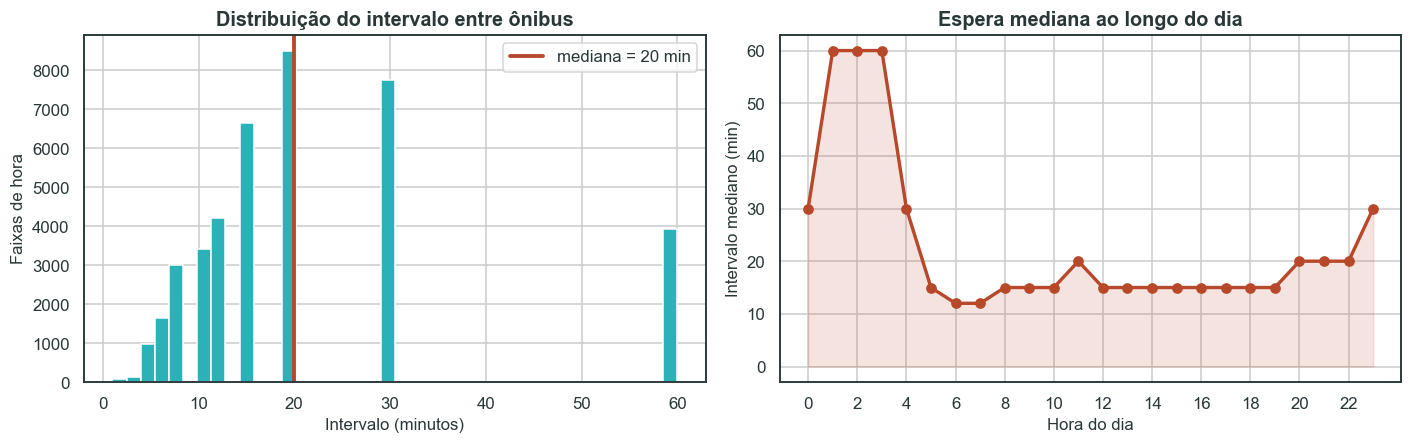

count    40337.00
mean        21.36
std         14.83
min          1.00
25%         12.00
50%         20.00
75%         30.00
max         60.00


In [3]:
alvo_bruto = frequencies["headway_secs"] / 60

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2))
eixos[0].hist(alvo_bruto, bins=40, color=AZUL, edgecolor="white")
eixos[0].axvline(alvo_bruto.median(), color=LARANJA, lw=2.5,
                 label=f"mediana = {alvo_bruto.median():.0f} min")
eixos[0].set(title="Distribuição do intervalo entre ônibus",
             xlabel="Intervalo (minutos)", ylabel="Faixas de hora")
eixos[0].legend()

por_hora = frequencies.assign(
    hora=frequencies["start_time"].str.slice(0, 2).astype(int) % 24,
    minutos=alvo_bruto).groupby("hora")["minutos"].median()
eixos[1].plot(por_hora.index, por_hora.values, marker="o", color=LARANJA, lw=2.2)
eixos[1].fill_between(por_hora.index, por_hora.values, alpha=0.15, color=LARANJA)
eixos[1].set(title="Espera mediana ao longo do dia",
             xlabel="Hora do dia", ylabel="Intervalo mediano (min)", xticks=range(0, 24, 2))
plt.tight_layout(); plt.savefig(FIG / "01_distribuicao_alvo.png"); plt.show()

print(alvo_bruto.describe().round(2).to_string())

A espera mediana cai para cerca de 15 minutos nos picos e **dobra na madrugada**, quando o cidadão está mais exposto no ponto. É essa variação que o totem precisa comunicar.

---
## 2. Preparação dos dados e engenharia de atributos

O GTFS é relacional: o intervalo está em `frequencies.txt`, e o que o explica está distribuído nas outras tabelas. A preparação as reúne e cria atributos que descrevem **a forma da linha** e **o momento do dia**.

**Decisão:** manter apenas `route_type == 3` (ônibus). O arquivo traz 9 linhas de metrô e 7 de trem, que seguem outra lógica de operação e somam menos de 1,2% das linhas; incluí-las contaminaria a resposta sobre o ponto de ônibus.

In [4]:
RAIO_TERRA_KM = 6371.0
SE_LAT, SE_LON = -23.5505, -46.6333   # Praça da Sé, marco zero de São Paulo

# As oito cores oficiais das linhas correspondem às áreas de operação da SPTrans
AREAS = {"509E2F": "Noroeste", "002F6C": "Norte",    "FFD100": "Nordeste",
         "DA291C": "Leste",    "006341": "Sudeste",  "0082BA": "Sul",
         "782F40": "Sudoeste", "FF671F": "Oeste"}


def haversine(lat1, lon1, lat2, lon2):
    # Distância em km entre dois pontos geográficos
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlbd = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlbd / 2) ** 2
    return 2 * RAIO_TERRA_KM * np.arcsin(np.sqrt(a))


def hhmmss_para_min(serie):
    # GTFS usa horas acima de 24 para viagens que cruzam a meia-noite
    partes = serie.str.split(":", expand=True).astype(int)
    return partes[0] * 60 + partes[1] + partes[2] / 60


def faixa_do_dia(hora):
    if hora < 5:  return "madrugada"
    if hora < 9:  return "pico_manha"
    if hora < 12: return "entrepico_manha"
    if hora < 15: return "almoco"
    if hora < 17: return "entrepico_tarde"
    if hora < 21: return "pico_tarde"
    return "noite"

In [5]:
def atributos_da_viagem(stop_times, stops):
    # Resume cada viagem: tamanho, duração, extensão e posição na cidade
    st = stop_times.copy()
    st["stop_sequence"] = st["stop_sequence"].astype(int)
    st = st.sort_values(["trip_id", "stop_sequence"])
    st["min_chegada"] = hhmmss_para_min(st["arrival_time"])
    st = st.join(stops.set_index("stop_id")[["stop_lat", "stop_lon"]], on="stop_id")

    g = st.groupby("trip_id")
    v = pd.DataFrame({
        "n_paradas": g.size(),
        "duracao_programada_min": g["min_chegada"].max() - g["min_chegada"].min(),
        "lat_origem": g["stop_lat"].first(), "lon_origem": g["stop_lon"].first(),
        "lat_destino": g["stop_lat"].last(), "lon_destino": g["stop_lon"].last(),
    })

    # extensão real: soma das distâncias entre paradas consecutivas
    anterior = st.groupby("trip_id")[["stop_lat", "stop_lon"]].shift(1)
    trecho = haversine(anterior["stop_lat"], anterior["stop_lon"],
                       st["stop_lat"], st["stop_lon"])
    v["extensao_km"] = trecho.groupby(st["trip_id"]).sum()

    v["lat_media"] = (v["lat_origem"] + v["lat_destino"]) / 2
    v["lon_media"] = (v["lon_origem"] + v["lon_destino"]) / 2
    v["dist_centro_km"] = haversine(v["lat_media"], v["lon_media"], SE_LAT, SE_LON)
    v["dist_origem_destino_km"] = haversine(v["lat_origem"], v["lon_origem"],
                                            v["lat_destino"], v["lon_destino"])
    v["velocidade_media_kmh"] = np.where(v["duracao_programada_min"] > 0,
                                         v["extensao_km"] / (v["duracao_programada_min"] / 60), np.nan)
    v["sinuosidade"] = np.where(v["dist_origem_destino_km"] > 0.1,
                                v["extensao_km"] / v["dist_origem_destino_km"], np.nan)
    return v.reset_index()


viagens = atributos_da_viagem(stop_times, stops)
print(f"{len(viagens):,} viagens resumidas")
viagens.head(3)

2,268 viagens resumidas


,trip_id,n_paradas,duracao_programada_min,lat_origem,lon_origem,lat_destino,lon_destino,extensao_km,lat_media,lon_media,dist_centro_km,dist_origem_destino_km,velocidade_media_kmh,sinuosidade
0,1012-10-0,41,55.0,-23.431924,-46.787131,-23.435757,-46.786715,10.400620,-23.433840,-46.786923,20.339673,0.428318,11.346131,24.282466
1,1012-21-0,18,31.0,-23.431805,-46.787148,-23.431805,-46.787148,5.752496,-23.431805,-46.787148,20.502411,0.000000,11.133863,NaN
2,1014-10-0,76,111.0,-23.404417,-46.753344,-23.404417,-46.753344,23.248240,-23.404417,-46.753344,20.340968,0.000000,12.566616,NaN


In [6]:
def montar_dataset():
    df = (frequencies
          .merge(trips[["trip_id", "route_id", "service_id", "direction_id"]], on="trip_id")
          .merge(routes[["route_id", "route_short_name", "route_long_name",
                         "route_type", "route_color"]], on="route_id")
          .merge(viagens, on="trip_id"))

    df["route_type"] = df["route_type"].astype(int)
    df = df[df["route_type"] == 3].copy()                       # somente ônibus

    # --- momento do dia ---
    df["hora"] = df["start_time"].str.slice(0, 2).astype(int) % 24
    df["periodo"] = df["hora"].apply(faixa_do_dia)
    df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)        # hora é cíclica:
    df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)        # 23h e 0h são vizinhas

    # --- tipo de dia (service_id no formato U S D) ---
    df["opera_sabado"]  = df["service_id"].str[1].ne("_").astype(int)
    df["opera_domingo"] = df["service_id"].str[2].ne("_").astype(int)

    # --- identidade da linha ---
    df["direction_id"] = df["direction_id"].astype(int)
    df["linha_noturna"] = df["route_short_name"].str.startswith("N").astype(int)
    df["regiao_prefixo"] = df["route_short_name"].str[0]
    df["area_operacao"] = df["route_color"].map(AREAS).fillna("outra")

    nome = df["route_long_name"].str.lower()
    df["atende_terminal"] = nome.str.contains("term").astype(int)
    df["atende_metro"]    = nome.str.contains("metr").astype(int)
    df["atende_cptm"]     = nome.str.contains("cptm|esta[çc]ão|estacao").astype(int)

    # --- concorrência de oferta na parada de origem ---
    origem = (stop_times.assign(seq=stop_times["stop_sequence"].astype(int))
              .sort_values(["trip_id", "seq"]).groupby("trip_id")["stop_id"].first())
    df["stop_id_origem"] = df["trip_id"].map(origem)
    linhas_por_parada = (stop_times.merge(trips[["trip_id", "route_id"]], on="trip_id")
                         .groupby("stop_id")["route_id"].nunique())
    df["linhas_na_origem"] = df["stop_id_origem"].map(linhas_por_parada).fillna(1)

    # --- alvo ---
    df["headway_min"] = df["headway_secs"] / 60.0
    return df.reset_index(drop=True)


dados = montar_dataset()
print(f"Dataset final: {dados.shape[0]:,} registros × {dados.shape[1]} colunas")
print(f"{dados.route_id.nunique():,} linhas de ônibus · {dados.trip_id.nunique():,} viagens")

Dataset final: 39,777 registros × 39 colunas
1,309 linhas de ônibus · 2,236 viagens


### Densidade urbana ao redor da linha

Os atributos anteriores descrevem a linha. Falta descrever **o território por onde ela passa**: uma linha que atravessa um bairro denso, com muitas paradas e muitas outras linhas, opera sob demanda diferente de outra que corta uma região vazia.

O GTFS não publica demanda nem frota — que é o que determina o intervalo —, mas publica a geometria da rede inteira, o que permite construir um indicador indireto: **quantas paradas e quantas linhas existem ao redor de cada parada do trajeto**. Uma árvore k-d conta os vizinhos dentro de 500 m e de 1 km, e a média é tomada ao longo de todas as paradas da linha, não apenas da origem.

In [7]:
GRAUS_POR_KM = 1 / 111.0

def densidade_urbana():
    # rota -> paradas, e parada -> rotas (estrutura da rede, independe do alvo)
    st = stop_times.merge(trips[["trip_id", "route_id"]], on="trip_id")
    paradas_por_rota = st.groupby("route_id")["stop_id"].apply(lambda s: sorted(set(s)))
    n_rotas_na_parada = st.groupby("stop_id")["route_id"].nunique()

    coord = stops.dropna(subset=["stop_lat", "stop_lon"]).copy()
    arvore = cKDTree(coord[["stop_lat", "stop_lon"]].values)

    for raio in (0.5, 1.0):
        vizinhos = arvore.query_ball_point(coord[["stop_lat", "stop_lon"]].values,
                                           r=raio * GRAUS_POR_KM)
        coord[f"paradas_{raio}"] = [len(v) - 1 for v in vizinhos]
        coord[f"linhas_{raio}"] = [
            int(n_rotas_na_parada.reindex(coord["stop_id"].values[v]).fillna(0).sum())
            for v in vizinhos
        ]
    por_parada = coord.set_index("stop_id")[["paradas_0.5", "linhas_0.5",
                                             "paradas_1.0", "linhas_1.0"]]

    linhas = []
    for rota, paradas in paradas_por_rota.items():
        sub = por_parada.reindex(paradas).dropna()
        if len(sub) == 0:
            continue
        linhas.append({
            "route_id": rota,
            "dens_paradas_500m": sub["paradas_0.5"].mean(),
            "dens_linhas_500m": sub["linhas_0.5"].mean(),
            "dens_paradas_1km": sub["paradas_1.0"].mean(),
            "dens_linhas_1km": sub["linhas_1.0"].mean(),
            "dens_paradas_1km_max": sub["paradas_1.0"].max(),
            "rotas_por_parada_media": n_rotas_na_parada.reindex(paradas).fillna(1).mean(),
        })
    return pd.DataFrame(linhas)


densidade = densidade_urbana()
ATRIBUTOS_DENSIDADE = [c for c in densidade.columns if c != "route_id"]

dados = dados.merge(densidade, on="route_id", how="left")
dados[ATRIBUTOS_DENSIDADE] = dados[ATRIBUTOS_DENSIDADE].fillna(
    dados[ATRIBUTOS_DENSIDADE].median())

print(f"{len(ATRIBUTOS_DENSIDADE)} atributos de densidade para {len(densidade):,} linhas")
densidade[ATRIBUTOS_DENSIDADE].describe().loc[["mean", "min", "max"]].round(1)

6 atributos de densidade para 1,325 linhas


,dens_paradas_500m,dens_linhas_500m,dens_paradas_1km,dens_linhas_1km,dens_paradas_1km_max,rotas_por_parada_media
mean,19.9,109.6,71.1,348.4,124.7,8.9
min,4.3,10.7,12.1,27.9,19.0,1.0
max,53.2,245.0,171.4,851.0,234.0,21.0


In [8]:
# Limpeza: valores ausentes e consistência
ausentes = dados.isna().sum()
print("Colunas com valores ausentes:")
print(ausentes[ausentes > 0].to_string() if ausentes.any() else "  nenhuma")

# sinuosidade e velocidade ficam indefinidas em viagens circulares (origem = destino)
for col in ["velocidade_media_kmh", "sinuosidade"]:
    faltando = dados[col].isna().sum()
    dados[col] = dados[col].fillna(dados[col].median())
    print(f"  {col}: {faltando} preenchidos com a mediana ({dados[col].median():.2f})")

print(f"\nDuplicatas exatas: {dados.duplicated().sum()}")
print(f"Alvo fora da faixa plausível (0–120 min): {((dados.headway_min <= 0) | (dados.headway_min > 120)).sum()}")
print(f"\nAlvo headway_min — min {dados.headway_min.min():.0f} · "
      f"mediana {dados.headway_min.median():.0f} · média {dados.headway_min.mean():.1f} · "
      f"máx {dados.headway_min.max():.0f}")

Colunas com valores ausentes:
velocidade_media_kmh      17
sinuosidade             4373
  velocidade_media_kmh: 17 preenchidos com a mediana (9.20)
  sinuosidade: 4373 preenchidos com a mediana (1.46)

Duplicatas exatas: 0
Alvo fora da faixa plausível (0–120 min): 0

Alvo headway_min — min 2 · mediana 20 · média 21.5 · máx 60


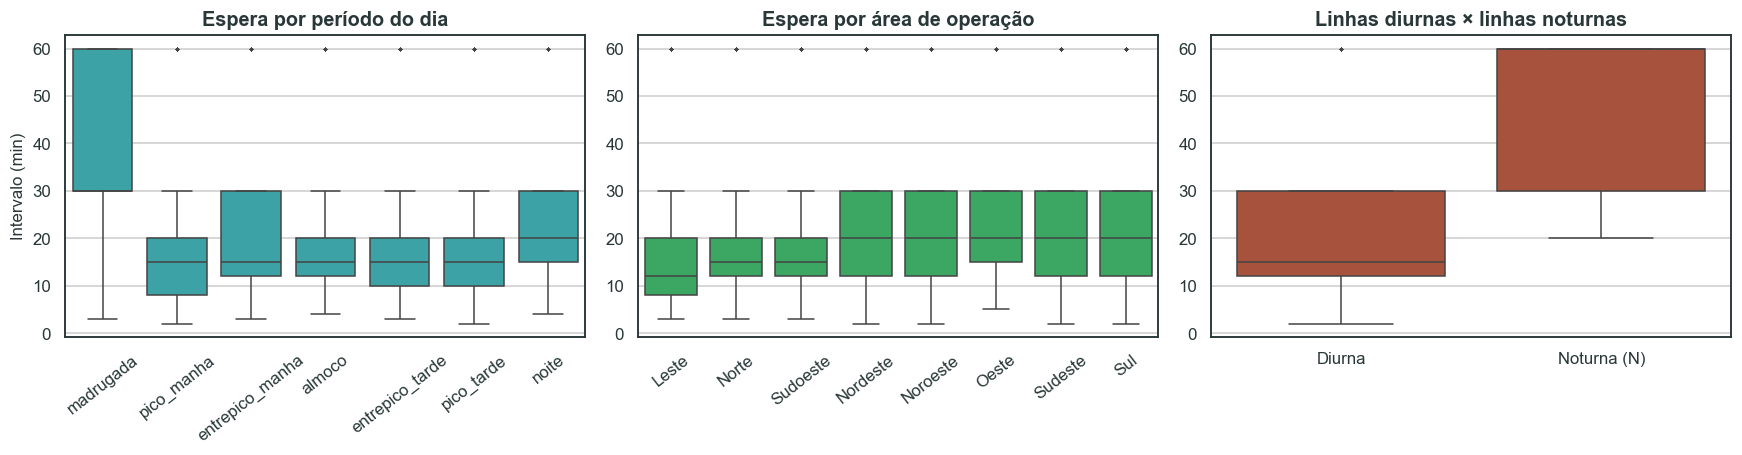

                 count  median  mean
periodo                             
madrugada         3808    30.0  40.8
pico_manha        7802    15.0  17.0
entrepico_manha   5635    15.0  20.2
almoco            5627    15.0  18.7
entrepico_tarde   3798    15.0  17.0
pico_tarde        7632    15.0  19.3
noite             5475    20.0  25.1


In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.3))

ordem = ["madrugada", "pico_manha", "entrepico_manha", "almoco",
         "entrepico_tarde", "pico_tarde", "noite"]
sns.boxplot(data=dados, x="periodo", y="headway_min", order=ordem,
            ax=eixos[0], color=AZUL, fliersize=1)
eixos[0].set(title="Espera por período do dia", xlabel="", ylabel="Intervalo (min)")
eixos[0].tick_params(axis="x", rotation=38)

ordem_area = dados.groupby("area_operacao")["headway_min"].median().sort_values().index
sns.boxplot(data=dados, x="area_operacao", y="headway_min", order=ordem_area,
            ax=eixos[1], color=VERDE, fliersize=1)
eixos[1].set(title="Espera por área de operação", xlabel="", ylabel="")
eixos[1].tick_params(axis="x", rotation=38)

sns.boxplot(data=dados, x="linha_noturna", y="headway_min", ax=eixos[2],
            color=LARANJA, fliersize=1)
eixos[2].set(title="Linhas diurnas × linhas noturnas", xlabel="", ylabel="",
             xticks=[0, 1], xticklabels=["Diurna", "Noturna (N)"])

plt.tight_layout(); plt.savefig(FIG / "02_exploracao.png"); plt.show()

print(dados.groupby("periodo")["headway_min"].agg(["count", "median", "mean"]).round(1).loc[ordem].to_string())

Três padrões reais aparecem e justificam os atributos escolhidos:

1. **Efeito do horário.** A madrugada tem a maior espera; os picos, a menor.
2. **Efeito da geografia.** A área Leste tem espera mediana de 12 minutos, enquanto Oeste, Sul e Nordeste ficam em 20 — uma diferença de oferta entre regiões da mesma cidade.
3. **As linhas noturnas são outro regime.** Mediana de 60 minutos contra 15 das diurnas, e é o público que mais depende de informação no ponto.

---
## 3. Divisão treino/teste: por que agrupar por linha

É a decisão metodológica central do trabalho.

Cada linha de ônibus aparece no dataset **cerca de 18 vezes** (uma por faixa de hora), e quase todos os atributos — extensão, nº de paradas, região — são constantes dentro da linha. Em uma divisão **aleatória** a mesma linha cairia dos dois lados: o modelo memorizaria o patamar de espera de cada linha no treino e o repetiria no teste, e a métrica resultante não mediria generalização. É vazamento de dados por grupo.

A divisão principal é, por isso, **agrupada por `route_id`** (`GroupShuffleSplit`): as linhas do teste nunca foram vistas no treino. É o cenário que o S.B.P. precisa resolver — estimar a espera de uma linha sem dado publicado.

A divisão aleatória é mantida **apenas como comparação**, retomada na seção 8.2.

In [10]:
ATRIBUTOS_NUMERICOS = [
    "hora", "hora_sin", "hora_cos", "n_paradas", "duracao_programada_min",
    "extensao_km", "dist_centro_km", "dist_origem_destino_km",
    "velocidade_media_kmh", "sinuosidade", "linhas_na_origem",
    "lat_media", "lon_media", "direction_id", "opera_sabado", "opera_domingo",
    "linha_noturna", "atende_terminal", "atende_metro", "atende_cptm",
]
ATRIBUTOS_NUMERICOS += ATRIBUTOS_DENSIDADE
ATRIBUTOS_CATEGORICOS = ["periodo", "area_operacao", "regiao_prefixo"]

X = dados[ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS]
y = dados["headway_min"]
grupos = dados["route_id"]

divisor = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMENTE)
idx_treino, idx_teste = next(divisor.split(X, y, grupos))

X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
g_treino = grupos.iloc[idx_treino]

print(f"Treino : {len(X_treino):>6,} registros · {g_treino.nunique():>5,} linhas")
print(f"Teste  : {len(X_teste):>6,} registros · {grupos.iloc[idx_teste].nunique():>5,} linhas")
print(f"Linhas em comum entre treino e teste: "
      f"{len(set(g_treino) & set(grupos.iloc[idx_teste]))}  ← tem de ser zero")
print(f"\nEspera média — treino {y_treino.mean():.1f} min · teste {y_teste.mean():.1f} min "
      f"(distribuições equivalentes)")

Treino : 31,923 registros · 1,047 linhas
Teste  :  7,854 registros ·   262 linhas
Linhas em comum entre treino e teste: 0  ← tem de ser zero

Espera média — treino 21.4 min · teste 22.1 min (distribuições equivalentes)


In [11]:
# Pré-processamento: árvores dispensam escala, modelos lineares a exigem.
def preparo(escalar):
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", ATRIBUTOS_NUMERICOS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ATRIBUTOS_CATEGORICOS),
    ])


def medir(nome, modelo, Xtr=X_treino, ytr=y_treino, Xte=X_teste, yte=y_teste, registro=None):
    inicio = time.time()
    modelo.fit(Xtr, ytr)
    p_tr, p_te = modelo.predict(Xtr), modelo.predict(Xte)
    linha = {
        "modelo": nome,
        "MAE_treino": mean_absolute_error(ytr, p_tr),
        "MAE_teste": mean_absolute_error(yte, p_te),
        "RMSE_treino": root_mean_squared_error(ytr, p_tr),
        "RMSE_teste": root_mean_squared_error(yte, p_te),
        "R2_treino": r2_score(ytr, p_tr),
        "R2_teste": r2_score(yte, p_te),
        "segundos": time.time() - inicio,
    }
    if registro is not None:
        registro.append(linha)
    return linha

---
## 4. O teto do problema

Antes de treinar, cabe medir **quanto do alvo é previsível**. A variância do intervalo de espera se decompõe em duas partes:

- **entre linhas** — o patamar de cada linha: a 1012-10 passa de 20 em 20 minutos, a 8000-10 de 8 em 8;
- **dentro da linha** — como esse patamar varia ao longo do dia.

A decomposição indica onde está a dificuldade e evita esforço onde não há margem a ganhar.

In [12]:
media_por_linha = dados.groupby("route_id")["headway_min"].transform("mean")
var_total = dados["headway_min"].var()
var_entre = media_por_linha.var()
var_dentro = (dados["headway_min"] - media_por_linha).var()

print(f"Variância total do alvo            : {var_total:7.1f}")
print(f"  entre linhas (patamar da linha)  : {var_entre:7.1f}  = {var_entre/var_total*100:4.1f}%")
print(f"  dentro da linha (perfil horário) : {var_dentro:7.1f}  = {var_dentro/var_total*100:4.1f}%")

Variância total do alvo            :   220.2
  entre linhas (patamar da linha)  :   118.2  = 53.7%
  dentro da linha (perfil horário) :   102.0  = 46.3%


Mais da metade da variância está **entre linhas**: a dificuldade não é descrever a variação da espera ao longo do dia, mas inferir o patamar de uma linha que o modelo nunca viu.

Para medir o teto, o conjunto de teste é avaliado com **oráculos** — previsores que recebem informação indisponível ao modelo.

In [13]:
def avaliar_simples(nome, previsao, observacao=""):
    print(f"{nome:<50} R² {r2_score(y_teste, previsao):6.3f}   MAE {mean_absolute_error(y_teste, previsao):5.2f} {observacao}")


teste = dados.iloc[idx_teste]
treino = dados.iloc[idx_treino]
perfil_horario = treino.groupby("hora")["headway_min"].mean()

print("Todos avaliados no mesmo conjunto de teste, de linhas inéditas:\n")
avaliar_simples("Chute: mediana do treino", np.full(len(y_teste), y_treino.median()))
avaliar_simples("Só o perfil horário médio da cidade",
                teste["hora"].map(perfil_horario).values)

perfil_tipo = treino.groupby(["linha_noturna", "opera_domingo", "hora"])["headway_min"].mean()
previsao_tipo = pd.Series(
    teste.set_index(["linha_noturna", "opera_domingo", "hora"]).index.map(perfil_tipo)
).astype(float).fillna(y_treino.mean()).values
avaliar_simples("Perfil horário × tipo de linha", previsao_tipo, "← teto do que é trivial")

print()
avaliar_simples("ORÁCULO: patamar verdadeiro de cada linha de teste",
                teste.groupby("route_id")["headway_min"].transform("mean").values,
                "← exige conhecer a linha")
avaliar_simples("ORÁCULO: patamar verdadeiro + perfil horário",
                (teste.groupby("route_id")["headway_min"].transform("mean")
                 + teste["hora"].map(perfil_horario - y_treino.mean())).values,
                "← TETO ABSOLUTO")

Todos avaliados no mesmo conjunto de teste, de linhas inéditas:

Chute: mediana do treino                           R² -0.019   MAE 10.48 
Só o perfil horário médio da cidade                R²  0.215   MAE  9.67 
Perfil horário × tipo de linha                     R²  0.350   MAE  8.72 ← teto do que é trivial

ORÁCULO: patamar verdadeiro de cada linha de teste R²  0.554   MAE  6.42 ← exige conhecer a linha


ORÁCULO: patamar verdadeiro + perfil horário       R²  0.625   MAE  5.66 ← TETO ABSOLUTO


Os oráculos delimitam o intervalo possível. Um modelo que não conhece a linha precisa superar o perfil horário por tipo de linha, e nenhum modelo alcança o teto absoluto, que exige conhecer de antemão o patamar de cada linha de teste.

**É entre esses dois valores que o resultado precisa cair.**

---
## 5. Escolha do modelo e da função-objetivo

Antes de ajustar hiperparâmetros, quatro alternativas são comparadas na mesma divisão, para que a escolha venha de evidência:

- **Linha de base (mediana)** — o que o cidadão já infere sozinho: "o ônibus costuma passar de 20 em 20 minutos". É o mínimo a superar.
- **Ridge** — modelo linear regularizado.
- **Random Forest** — árvores em paralelo, robusto a relações não lineares.
- **XGBoost** — árvores em sequência, cada uma corrigindo o erro da anterior.

A relação entre espera, hora e geografia **não é linear** — a madrugada rompe o padrão, as linhas noturnas são outro regime, a periferia difere do centro — e envolve interações entre atributos, o que favorece modelos de árvore.

In [14]:
comparacao = []

medir("Linha de base (mediana)", DummyRegressor(strategy="median"), registro=comparacao)
medir("Ridge (linear)",
      Pipeline([("prep", preparo(True)), ("mod", Ridge(alpha=1.0))]), registro=comparacao)
medir("Random Forest",
      Pipeline([("prep", preparo(False)),
                ("mod", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                              random_state=SEMENTE, n_jobs=-1))]), registro=comparacao)
medir("XGBoost",
      Pipeline([("prep", preparo(False)),
                ("mod", XGBRegressor(n_estimators=600, max_depth=6, learning_rate=0.08,
                                     subsample=0.8, colsample_bytree=0.8,
                                     objective="reg:absoluteerror", random_state=SEMENTE,
                                     n_jobs=-1, tree_method="hist"))]), registro=comparacao)

tabela_modelos = pd.DataFrame(comparacao).set_index("modelo").round(2)
tabela_modelos

,MAE_treino,MAE_teste,RMSE_treino,RMSE_teste,R2_treino,R2_teste,segundos
modelo,,,,,,,
Linha de base (mediana),10.23,10.48,14.82,15.29,-0.01,-0.02,0.01
Ridge (linear),8.30,8.40,11.65,11.79,0.38,0.39,0.17
Random Forest,2.66,8.18,4.52,11.38,0.91,0.44,11.91
XGBoost,3.59,7.41,6.82,10.86,0.79,0.49,4.62


O **XGBoost** vence em erro de teste e é cerca de três vezes mais rápido que a Random Forest, o que pesa porque ele será treinado dezenas de vezes na busca de hiperparâmetros. É o modelo escolhido.

A tabela também mostra que o ganho sobre o Ridge é modesto. Prever a espera de uma linha **nunca vista** é genuinamente difícil: o intervalo é determinado pela demanda e pela frota alocada, informação que o GTFS não publica, e o modelo trabalha com indícios indiretos — geografia, extensão, integrações. As seções 4 e 8 retomam esse limite.

Resta decidir a **função-objetivo**, que depende de qual tipo de erro é mais custoso para o cidadão.

In [15]:
objetivos = []
for rotulo, alvo in [("Erro absoluto (mediana)", dict(objective="reg:absoluteerror")),
                     ("Quantil 0,60", dict(objective="reg:quantileerror", quantile_alpha=0.60)),
                     ("Quantil 0,65", dict(objective="reg:quantileerror", quantile_alpha=0.65)),
                     ("Erro quadrático (média)", dict(objective="reg:squarederror"))]:
    modelo = Pipeline([("prep", preparo(False)),
                       ("mod", XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.03,
                                            subsample=0.8, colsample_bytree=0.8,
                                            random_state=SEMENTE, n_jobs=-1,
                                            tree_method="hist", **alvo))])
    modelo.fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)
    objetivos.append({
        "funcao_objetivo": rotulo,
        "MAE": mean_absolute_error(y_teste, previsto),
        "RMSE": root_mean_squared_error(y_teste, previsto),
        "R2": r2_score(y_teste, previsto),
        "vies_min": (y_teste - previsto).mean(),
        "subestima_%": (previsto < y_teste).mean() * 100,
    })

pd.DataFrame(objetivos).set_index("funcao_objetivo").round(2)

,MAE,RMSE,R2,vies_min,subestima_%
funcao_objetivo,,,,,
Erro absoluto (mediana),7.47,11.12,0.46,2.03,47.50
"Quantil 0,60",8.01,11.64,0.41,1.21,42.95
"Quantil 0,65",8.01,11.46,0.43,0.40,40.23
Erro quadrático (média),7.59,10.64,0.51,-0.09,41.23


A coluna `vies_min` é decisiva. O erro absoluto minimiza o MAE, mas produz um modelo que **subestima a espera em cerca de 2 minutos na média**, porque a distribuição é assimétrica à direita e a mediana fica abaixo da média.

Subestimar e superestimar não têm o mesmo custo para quem está na calçada. Anunciar 10 minutos quando a espera é de 20 mantém o passageiro no ponto sob premissa falsa; o erro para cima apenas o surpreende. **Um modelo que erra sistematicamente para baixo induz o passageiro ao erro.**

O erro quadrático zera esse viés a um custo de poucos centésimos de minuto no MAE e devolve um modelo centrado. É o adotado.

---
## 6. Busca de hiperparâmetros

A busca cobre **3 hiperparâmetros** em grade completa, somando **18 combinações** (acima do mínimo de 10):

| Hiperparâmetro | Valores | O que controla |
| :--- | :--- | :--- |
| `max_depth` | 3, 5, 7 | Profundidade da árvore: quanta interação entre atributos ela capta |
| `learning_rate` | 0,03 · 0,08 · 0,15 | Quanto cada árvore corrige — passos menores generalizam melhor |
| `n_estimators` | 300, 600 | Quantas árvores em sequência |

A validação cruzada usa **`GroupKFold` com 5 dobras, aplicada somente ao conjunto de treino**, mantendo o agrupamento por linha também dentro da validação. Assim nenhuma linha aparece ao mesmo tempo na dobra de ajuste e na de validação, e **o conjunto de teste não participa de nenhuma decisão**.

São 18 combinações × 5 dobras = **90 ajustes**.

In [16]:
grade = {
    "mod__max_depth":     [3, 5, 7],
    "mod__learning_rate": [0.03, 0.08, 0.15],
    "mod__n_estimators":  [300, 600],
}

pipeline_xgb = Pipeline([
    ("prep", preparo(False)),
    ("mod", XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                         objective="reg:squarederror", random_state=SEMENTE,
                         n_jobs=-1, tree_method="hist")),
])

busca = GridSearchCV(
    pipeline_xgb, grade,
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=1, verbose=1, return_train_score=True,
)

inicio = time.time()
busca.fit(X_treino, y_treino, groups=g_treino)
print(f"\n{len(busca.cv_results_['params'])} combinações testadas em {time.time()-inicio:.0f}s")
print(f"Melhor combinação: {busca.best_params_}")
print(f"MAE na validação cruzada: {-busca.best_score_:.2f} min")

Fitting 5 folds for each of 18 candidates, totalling 90 fits



18 combinações testadas em 128s
Melhor combinação: {'mod__learning_rate': 0.03, 'mod__max_depth': 7, 'mod__n_estimators': 300}
MAE na validação cruzada: 7.98 min


In [17]:
resultados_busca = (pd.DataFrame(busca.cv_results_)
    .assign(MAE_validacao=lambda d: -d["mean_test_score"],
            MAE_treino_cv=lambda d: -d["mean_train_score"],
            desvio=lambda d: d["std_test_score"])
    .rename(columns={"param_mod__max_depth": "max_depth",
                     "param_mod__learning_rate": "learning_rate",
                     "param_mod__n_estimators": "n_estimators"})
    [["max_depth", "learning_rate", "n_estimators",
      "MAE_treino_cv", "MAE_validacao", "desvio"]]
    .sort_values("MAE_validacao").round(3).reset_index(drop=True))

resultados_busca.index += 1
print("As 18 combinações, da melhor para a pior (MAE em minutos):")
resultados_busca

As 18 combinações, da melhor para a pior (MAE em minutos):


,max_depth,learning_rate,n_estimators,MAE_treino_cv,MAE_validacao,desvio
1,7,0.03,300,4.124,7.980,0.552
2,5,0.03,300,5.423,7.987,0.525
3,5,0.03,600,4.549,8.009,0.560
4,7,0.03,600,3.409,8.024,0.555
5,7,0.08,300,3.179,8.096,0.607
6,5,0.08,300,4.280,8.131,0.586
7,7,0.08,600,2.556,8.178,0.625
8,3,0.03,600,6.226,8.179,0.518
9,3,0.03,300,7.023,8.187,0.480
10,5,0.08,600,3.745,8.208,0.580


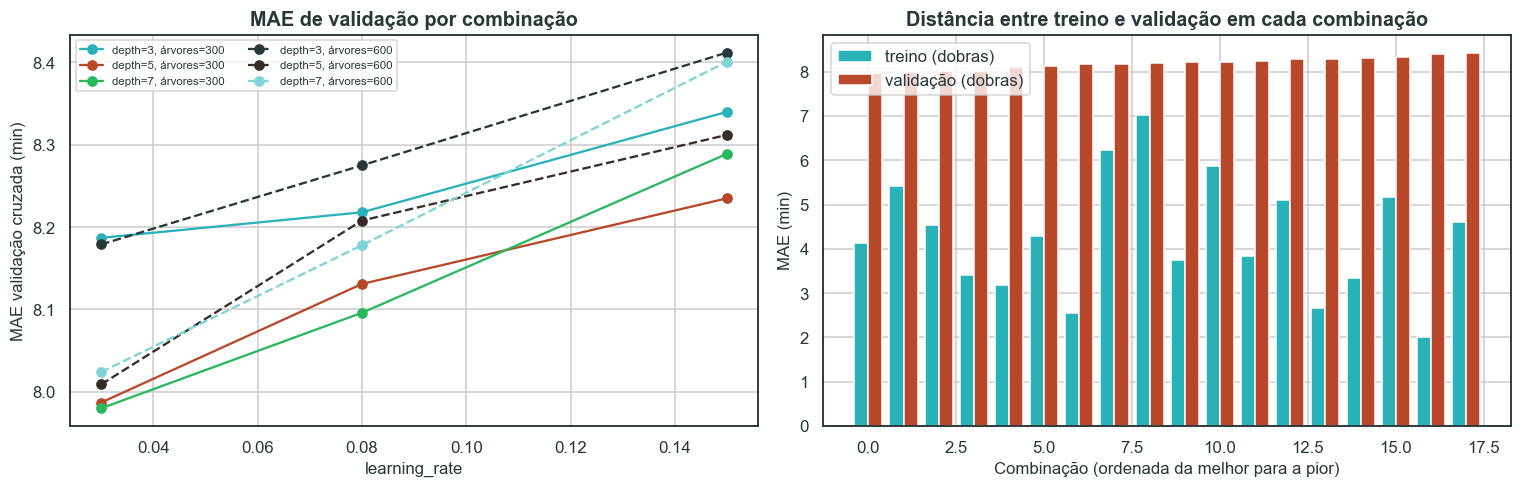

In [18]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))

for n_arv, grupo in resultados_busca.groupby("n_estimators"):
    for prof, sub in grupo.groupby("max_depth"):
        sub = sub.sort_values("learning_rate")
        eixos[0].plot(sub["learning_rate"], sub["MAE_validacao"], marker="o",
                      ls="-" if n_arv == 300 else "--",
                      label=f"depth={prof}, árvores={n_arv}")
eixos[0].set(title="MAE de validação por combinação",
             xlabel="learning_rate", ylabel="MAE validação cruzada (min)")
eixos[0].legend(fontsize=7.5, ncol=2)

largura = np.arange(len(resultados_busca))
eixos[1].bar(largura - 0.2, resultados_busca["MAE_treino_cv"], 0.4, label="treino (dobras)", color=AZUL)
eixos[1].bar(largura + 0.2, resultados_busca["MAE_validacao"], 0.4, label="validação (dobras)", color=LARANJA)
eixos[1].set(title="Distância entre treino e validação em cada combinação",
             xlabel="Combinação (ordenada da melhor para a pior)", ylabel="MAE (min)")
eixos[1].legend()

plt.tight_layout(); plt.savefig(FIG / "03_busca_hiperparametros.png"); plt.show()

A grade apresenta o comportamento esperado: as combinações mais profundas e com passo maior **ajustam melhor o treino e pioram na validação**, e a distância entre as duas barras cresce. A busca seleciona uma configuração mais contida, que erra um pouco mais no treino e acerta mais em linhas inéditas.

---
## 7. Resultados

O modelo escolhido é reajustado em todo o treino e avaliado, pela primeira vez, no conjunto de teste — as linhas que ele nunca viu.

In [19]:
modelo_final = busca.best_estimator_

pred_treino = modelo_final.predict(X_treino)
pred_teste  = modelo_final.predict(X_teste)

desempenho = pd.DataFrame({
    "Treino": [mean_absolute_error(y_treino, pred_treino),
               root_mean_squared_error(y_treino, pred_treino),
               r2_score(y_treino, pred_treino)],
    "Teste (linhas inéditas)": [mean_absolute_error(y_teste, pred_teste),
                                root_mean_squared_error(y_teste, pred_teste),
                                r2_score(y_teste, pred_teste)],
}, index=["MAE (min)", "RMSE (min)", "R²"]).round(3)

base_mae = mean_absolute_error(y_teste, np.full(len(y_teste), y_treino.median()))
desempenho["Linha de base (mediana)"] = [base_mae,
    root_mean_squared_error(y_teste, np.full(len(y_teste), y_treino.median())),
    r2_score(y_teste, np.full(len(y_teste), y_treino.median()))]

print(desempenho.round(2).to_string())
print(f"\nRedução de erro sobre a linha de base: "
      f"{(1 - desempenho.loc['MAE (min)','Teste (linhas inéditas)']/base_mae)*100:.1f}%")

            Treino  Teste (linhas inéditas)  Linha de base (mediana)
MAE (min)     4.31                     7.59                    10.48
RMSE (min)    6.54                    10.64                    15.29
R²            0.80                     0.51                    -0.02

Redução de erro sobre a linha de base: 27.6%


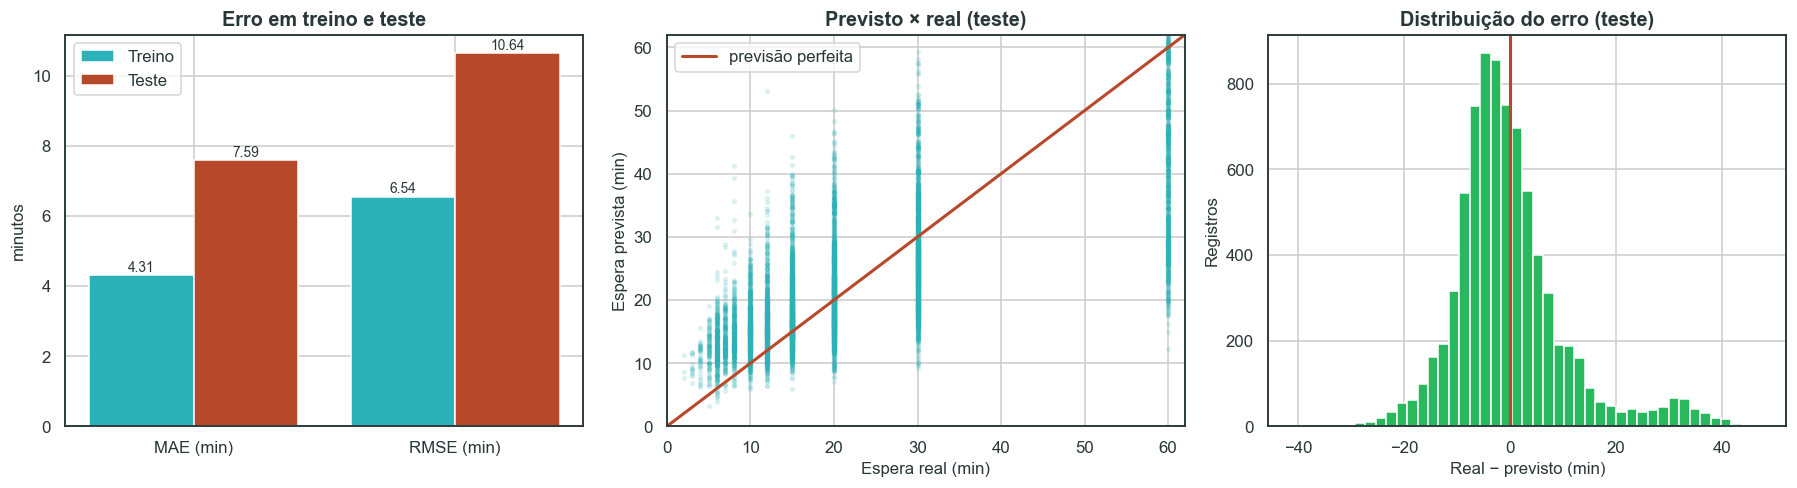

Erro de até  5 minutos: 46.2% das previsões
Erro de até 10 minutos: 75.9% das previsões
Viés médio (tendência a sub/superestimar): -0.09 min


In [20]:
fig, eixos = plt.subplots(1, 3, figsize=(16.5, 4.6))

# (a) treino × teste lado a lado
metricas = ["MAE (min)", "RMSE (min)"]
pos = np.arange(len(metricas))
eixos[0].bar(pos - 0.2, desempenho.loc[metricas, "Treino"], 0.4, label="Treino", color=AZUL)
eixos[0].bar(pos + 0.2, desempenho.loc[metricas, "Teste (linhas inéditas)"], 0.4,
             label="Teste", color=LARANJA)
for i, m in enumerate(metricas):
    eixos[0].text(i - 0.2, desempenho.loc[m, "Treino"] + 0.12,
                  f"{desempenho.loc[m,'Treino']:.2f}", ha="center", fontsize=9)
    eixos[0].text(i + 0.2, desempenho.loc[m, "Teste (linhas inéditas)"] + 0.12,
                  f"{desempenho.loc[m,'Teste (linhas inéditas)']:.2f}", ha="center", fontsize=9)
eixos[0].set(title="Erro em treino e teste", xticks=pos, xticklabels=metricas, ylabel="minutos")
eixos[0].legend()

# (b) previsto × real
eixos[1].scatter(y_teste, pred_teste, s=6, alpha=0.12, color=AZUL)
lim = [0, 62]
eixos[1].plot(lim, lim, color=LARANJA, lw=2, label="previsão perfeita")
eixos[1].set(title="Previsto × real (teste)", xlabel="Espera real (min)",
             ylabel="Espera prevista (min)", xlim=lim, ylim=lim)
eixos[1].legend()

# (c) resíduos
residuos = y_teste - pred_teste
eixos[2].hist(residuos, bins=45, color=VERDE, edgecolor="white")
eixos[2].axvline(0, color=LARANJA, lw=2)
eixos[2].set(title="Distribuição do erro (teste)",
             xlabel="Real − previsto (min)", ylabel="Registros")

plt.tight_layout(); plt.savefig(FIG / "04_resultados.png"); plt.show()

dentro5  = (residuos.abs() <= 5).mean() * 100
dentro10 = (residuos.abs() <= 10).mean() * 100
print(f"Erro de até  5 minutos: {dentro5:.1f}% das previsões")
print(f"Erro de até 10 minutos: {dentro10:.1f}% das previsões")
print(f"Viés médio (tendência a sub/superestimar): {residuos.mean():+.2f} min")

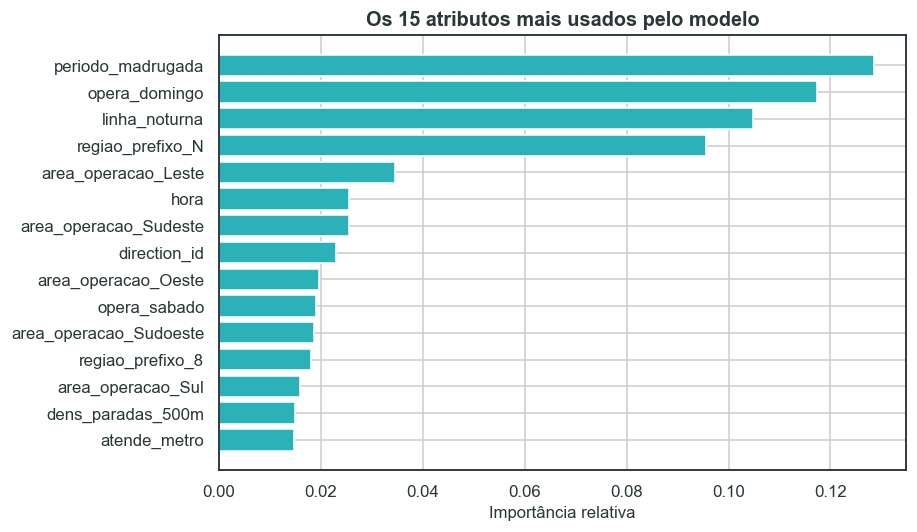

periodo_madrugada        0.1285
opera_domingo            0.1174
linha_noturna            0.1048
regiao_prefixo_N         0.0956
area_operacao_Leste      0.0347
hora                     0.0256
area_operacao_Sudeste    0.0256
direction_id             0.0229


In [21]:
# Quais atributos o modelo usa
nomes = modelo_final.named_steps["prep"].get_feature_names_out()
nomes = [n.split("__", 1)[-1] for n in nomes]
importancias = (pd.Series(modelo_final.named_steps["mod"].feature_importances_, index=nomes)
                .sort_values(ascending=False).head(15))

plt.figure(figsize=(8.5, 5))
plt.barh(importancias.index[::-1], importancias.values[::-1], color=AZUL)
plt.title("Os 15 atributos mais usados pelo modelo")
plt.xlabel("Importância relativa")
plt.tight_layout(); plt.savefig(FIG / "05_importancias.png"); plt.show()

print(importancias.head(8).round(4).to_string())

---
## 8. Os limites do modelo, medidos

### 8.1 Overfitting: a distância entre treino e teste

O erro no treino é bem menor do que no teste. Essa distância é **overfitting**: o XGBoost memoriza parte do patamar de espera das linhas de treino. A busca de hiperparâmetros reduziu o problema, selecionando a configuração mais contida da grade, mas não poderia eliminá-lo — o atributo que explicaria a diferença entre duas linhas semelhantes, a **demanda de passageiros e a frota alocada**, não está no GTFS.

### 8.2 O vazamento evitado

O experimento que sustenta a metodologia: o **mesmo modelo**, com os **mesmos hiperparâmetros**, avaliado com divisão aleatória em vez de agrupada.

                                 Divisão agrupada por linha (correta)  Divisão aleatória (com vazamento)
MAE (min)                                                        7.59                               5.28
RMSE (min)                                                      10.64                               8.15
R²                                                               0.51                               0.70
Linhas presentes nos dois lados                                  0.00                            1207.00


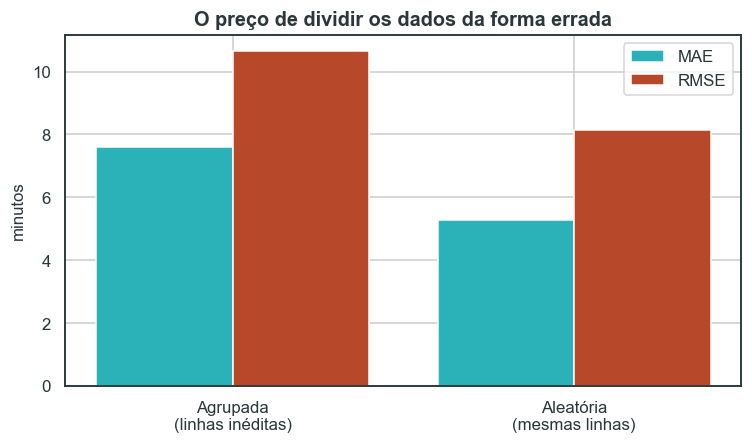

In [22]:
# Mesmo modelo, mesma configuração — só muda a forma de dividir os dados
idx_tr_aleat, idx_te_aleat = train_test_split(
    np.arange(len(X)), test_size=0.20, random_state=SEMENTE)

modelo_aleatorio = Pipeline([
    ("prep", preparo(False)),
    ("mod", XGBRegressor(**{k.replace("mod__", ""): v for k, v in busca.best_params_.items()},
                         subsample=0.8, colsample_bytree=0.8,
                         objective="reg:squarederror", random_state=SEMENTE,
                         n_jobs=-1, tree_method="hist")),
])
modelo_aleatorio.fit(X.iloc[idx_tr_aleat], y.iloc[idx_tr_aleat])
pred_aleat = modelo_aleatorio.predict(X.iloc[idx_te_aleat])

linhas_repetidas = len(set(grupos.iloc[idx_tr_aleat]) & set(grupos.iloc[idx_te_aleat]))

vazamento = pd.DataFrame({
    "Divisão agrupada por linha (correta)": [
        mean_absolute_error(y_teste, pred_teste),
        root_mean_squared_error(y_teste, pred_teste),
        r2_score(y_teste, pred_teste), 0],
    "Divisão aleatória (com vazamento)": [
        mean_absolute_error(y.iloc[idx_te_aleat], pred_aleat),
        root_mean_squared_error(y.iloc[idx_te_aleat], pred_aleat),
        r2_score(y.iloc[idx_te_aleat], pred_aleat), linhas_repetidas],
}, index=["MAE (min)", "RMSE (min)", "R²", "Linhas presentes nos dois lados"])

print(vazamento.round(2).to_string())

plt.figure(figsize=(7, 4.2))
pos = np.arange(2)
plt.bar(pos - 0.2, vazamento.loc["MAE (min)"], 0.4, color=AZUL, label="MAE")
plt.bar(pos + 0.2, vazamento.loc["RMSE (min)"], 0.4, color=LARANJA, label="RMSE")
plt.xticks(pos, ["Agrupada\n(linhas inéditas)", "Aleatória\n(mesmas linhas)"])
plt.ylabel("minutos"); plt.title("O preço de dividir os dados da forma errada")
plt.legend(); plt.tight_layout(); plt.savefig(FIG / "06_vazamento.png"); plt.show()

A divisão aleatória produz erro muito menor e R² muito mais alto. **Esse resultado seria falso**: mede a capacidade do modelo de repetir o que já viu, não de responder sobre uma linha nova, e as linhas aparecem nos dois lados da divisão, como a última coluna mostra.

Relatar o número otimista atribuiria ao S.B.P. uma precisão que ele não entrega em campo.

### 8.3 Contribuição do melhor atributo novo

Entre os atributos construídos, os de **densidade urbana** foram os únicos realmente novos; o restante já descrevia a linha. A contribuição é medida treinando o modelo vencedor com e sem esse bloco.

In [23]:
parametros_vencedores = {k.replace("mod__", ""): v for k, v in busca.best_params_.items()}

def medir_conjunto(nome, numericos):
    colunas = numericos + ATRIBUTOS_CATEGORICOS
    modelo = Pipeline([
        ("prep", ColumnTransformer([
            ("num", "passthrough", numericos),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             ATRIBUTOS_CATEGORICOS),
        ])),
        ("mod", XGBRegressor(**parametros_vencedores, subsample=0.8, colsample_bytree=0.8,
                             objective="reg:squarederror", random_state=SEMENTE,
                             n_jobs=-1, tree_method="hist")),
    ])
    modelo.fit(X_treino[colunas], y_treino)
    previsto = modelo.predict(X_teste[colunas])
    return {"conjunto": nome,
            "atributos": len(colunas),
            "MAE": mean_absolute_error(y_teste, previsto),
            "RMSE": root_mean_squared_error(y_teste, previsto),
            "R2": r2_score(y_teste, previsto)}


sem_densidade = [c for c in ATRIBUTOS_NUMERICOS if c not in ATRIBUTOS_DENSIDADE]
ablacao = pd.DataFrame([
    medir_conjunto("Sem densidade urbana", sem_densidade),
    medir_conjunto("Com densidade urbana (modelo final)", ATRIBUTOS_NUMERICOS),
]).set_index("conjunto").round(3)

ganho = ablacao["R2"].iloc[1] - ablacao["R2"].iloc[0]
print(f"Ganho de R² atribuível à densidade urbana: {ganho:+.3f}")
print()
ablacao

Ganho de R² atribuível à densidade urbana: +0.045



,atributos,MAE,RMSE,R2
conjunto,,,,
Sem densidade urbana,23,7.891,11.111,0.462
Com densidade urbana (modelo final),29,7.587,10.637,0.507


O ganho é real, mas modesto, e coerente com o mecanismo: contar paradas e linhas ao redor informa sobre o adensamento do bairro, que se relaciona com demanda, mas é um indício indireto, e indício indireto não substitui a variável ausente.

### 8.4 O que a vizinhança não explica

O resultado negativo também fica registrado, porque informa sobre o problema.

A hipótese era usar, para estimar a espera de uma linha inédita, a espera das **outras linhas que passam pelas mesmas paradas**. Essa informação existe antes de a linha nova operar, e pode ser implementada sem vazamento, aprendendo os patamares das vizinhas apenas no conjunto de ajuste.

A hipótese foi testada e não se confirmou.

Linhas analisadas: 1,306
Correlação entre a espera da linha e a das suas vizinhas: +0.089
R² que esse atributo poderia entregar sozinho:            0.008


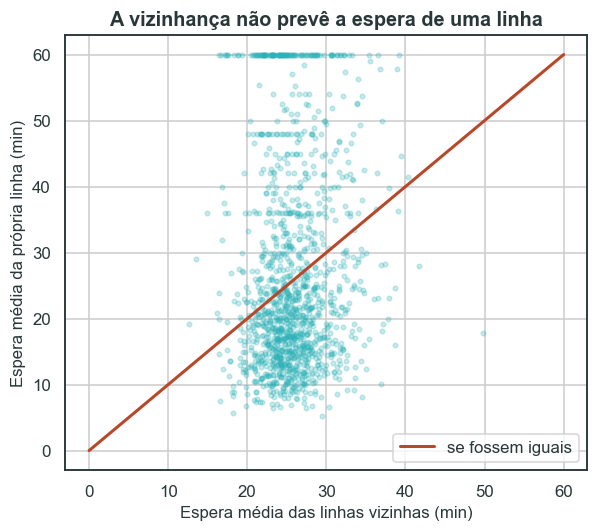

In [24]:
# Para cada linha, a espera média das vizinhas, ponderada pelo número de paradas
# compartilhadas: quem acompanha o trajeto inteiro pesa mais do que quem o cruza.
st_rotas = stop_times.merge(trips[["trip_id", "route_id"]], on="trip_id")
paradas_da_rota = st_rotas.groupby("route_id")["stop_id"].apply(set)
rotas_da_parada = st_rotas.groupby("stop_id")["route_id"].apply(set)
espera_da_rota = dados.groupby("route_id")["headway_min"].mean()

vizinhanca = {}
for rota in espera_da_rota.index:
    contador = Counter()
    for parada in paradas_da_rota.get(rota, set()):
        contador.update(r for r in rotas_da_parada.get(parada, set()) if r != rota)
    conhecidas = [(r, peso) for r, peso in contador.items() if r in espera_da_rota.index]
    if conhecidas:
        rotas_viz = [r for r, _ in conhecidas]
        pesos = np.array([p for _, p in conhecidas], dtype=float)
        vizinhanca[rota] = np.average(espera_da_rota[rotas_viz], weights=pesos)

comparado = pd.DataFrame({"espera_da_linha": espera_da_rota,
                          "espera_das_vizinhas": pd.Series(vizinhanca)}).dropna()
correlacao = comparado["espera_da_linha"].corr(comparado["espera_das_vizinhas"])

print(f"Linhas analisadas: {len(comparado):,}")
print(f"Correlação entre a espera da linha e a das suas vizinhas: {correlacao:+.3f}")
print(f"R² que esse atributo poderia entregar sozinho:            {correlacao**2:.3f}")

plt.figure(figsize=(5.6, 5))
plt.scatter(comparado["espera_das_vizinhas"], comparado["espera_da_linha"],
            s=9, alpha=0.25, color=AZUL)
plt.plot([0, 60], [0, 60], color=LARANJA, lw=2, label="se fossem iguais")
plt.xlabel("Espera média das linhas vizinhas (min)")
plt.ylabel("Espera média da própria linha (min)")
plt.title("A vizinhança não prevê a espera de uma linha")
plt.legend(); plt.tight_layout(); plt.savefig(FIG / "10_vizinhanca.png"); plt.show()

A dispersão não mostra estrutura: **a correlação é praticamente zero.** Duas linhas que percorrem as mesmas ruas podem ter intervalos completamente diferentes, por serem uma troncal e outra alimentadora. A oferta não se propaga entre linhas vizinhas.

O resultado confirma, por outro caminho, o diagnóstico da seção 4: o patamar de uma linha depende da **demanda e da frota alocada àquela linha**, e nada na geometria da rede substitui essa informação.

### 8.5 Desempenho em uma cidade desconhecida

A divisão agrupada por linha responde a uma pergunta específica: *uma linha nova, em uma cidade com dados*. O trabalho também afirmou que o modelo serviria a **cidades sem GTFS aberto** — pergunta diferente e mais dura, porque lá não há nenhuma linha conhecida da região.

Para medir isso, cada região de São Paulo é bloqueada por vez: todas as suas linhas saem do treino.

In [25]:
bloqueio = []
for regiao in ["6", "2", "5", "1"]:
    marca = dados["regiao_prefixo"].values == regiao
    if marca.sum() < 500:
        continue
    modelo_regiao = Pipeline([
        ("prep", preparo(False)),
        ("mod", XGBRegressor(**{k.replace("mod__", ""): v for k, v in busca.best_params_.items()},
                             subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror",
                             random_state=SEMENTE, n_jobs=-1, tree_method="hist")),
    ])
    modelo_regiao.fit(X[~marca], y[~marca])
    previsto = modelo_regiao.predict(X[marca])
    bloqueio.append({"regiao_bloqueada": regiao,
                     "linhas": dados.loc[marca, "route_id"].nunique(),
                     "registros": int(marca.sum()),
                     "MAE": mean_absolute_error(y[marca], previsto),
                     "R2": r2_score(y[marca], previsto)})

tabela_bloqueio = pd.DataFrame(bloqueio).set_index("regiao_bloqueada").round(3)
print("Desempenho quando uma região inteira nunca foi vista:\n")
print(tabela_bloqueio.to_string())
print(f"\nPara comparar — divisão agrupada por linha: "
      f"R² {desempenho.loc['R²','Teste (linhas inéditas)']:.3f}, "
      f"MAE {desempenho.loc['MAE (min)','Teste (linhas inéditas)']:.2f}")

Desempenho quando uma região inteira nunca foi vista:

                  linhas  registros    MAE     R2
regiao_bloqueada                                 
6                    219       7286  7.583  0.342
2                    158       5228  8.119  0.301
5                    137       4562  8.545  0.300
1                    107       3625  8.297  0.261

Para comparar — divisão agrupada por linha: R² 0.507, MAE 7.59


O desempenho cai de forma expressiva. Parte do acerto da divisão agrupada vinha de o modelo conhecer **outras linhas da mesma região**, e aprender, legitimamente, que determinada área da cidade opera com determinado intervalo.

Isso não invalida o resultado principal: para o caso de uso real do S.B.P. — um ponto em uma cidade cuja rede é conhecida — a divisão agrupada por linha é a avaliação correta. Mas a aplicação a uma cidade sem dado algum é **mais frágil do que o enunciado inicial sugeria**, e os dois números passam a ser registrados.

---
## 9. Faixa de predição calibrada

O modelo erra alguns minutos. Anunciar "14 minutos" no totem atribui a ele uma precisão que não tem; anunciar **"entre 8 e 25 minutos"** preserva a utilidade da informação, pois já distingue esperar de procurar outro caminho.

Dois modelos de quantil fornecem os extremos da faixa, mas quantis estimados não garantem cobertura e precisam de **calibração**. A predição conformal separa uma parte do treino para calibração e ajusta a largura até que a cobertura observada corresponda à prometida.

In [26]:
ALFA = 0.20   # faixa de 80%

# A calibração sai de dentro do treino, mantendo o agrupamento por linha:
# nenhuma linha aparece ao mesmo tempo no ajuste e na calibração.
divisor_cal = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=7)
i_ajuste, i_calib = next(divisor_cal.split(X_treino, y_treino, g_treino))
idx_ajuste, idx_calib = idx_treino[i_ajuste], idx_treino[i_calib]

def modelo_quantil(alpha):
    return Pipeline([
        ("prep", preparo(False)),
        ("mod", XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.03,
                             subsample=0.8, colsample_bytree=0.8,
                             objective="reg:quantileerror", quantile_alpha=alpha,
                             random_state=SEMENTE, n_jobs=-1, tree_method="hist")),
    ]).fit(X.iloc[idx_ajuste], y.iloc[idx_ajuste])

modelo_inferior = modelo_quantil(ALFA / 2)
modelo_superior = modelo_quantil(1 - ALFA / 2)

def faixa(indices, folga=0.0):
    baixo = modelo_inferior.predict(X.iloc[indices])
    alto = modelo_superior.predict(X.iloc[indices])
    baixo, alto = np.minimum(baixo, alto), np.maximum(baixo, alto)
    return np.maximum(baixo - folga, 0), alto + folga

# a folga conformal vem dos erros na calibração, nunca do teste
baixo_cal, alto_cal = faixa(idx_calib)
reais_cal = y.iloc[idx_calib].values
erros = np.maximum(baixo_cal - reais_cal, reais_cal - alto_cal)
folga = np.quantile(erros, min(1.0, (1 - ALFA) * (1 + 1 / len(erros))))

for rotulo, f in [("Quantis crus, sem calibração", 0.0), ("Conformalizado", folga)]:
    baixo, alto = faixa(idx_teste, f)
    cobertura = ((y_teste.values >= baixo) & (y_teste.values <= alto)).mean() * 100
    print(f"{rotulo:<32} cobertura {cobertura:5.1f}%   largura mediana {np.median(alto-baixo):5.1f} min")
print(f"\nFolga conformal: {folga:.2f} min   ·   cobertura prometida: {(1-ALFA)*100:.0f}%")

Quantis crus, sem calibração     cobertura  69.9%   largura mediana  19.5 min
Conformalizado                   cobertura  79.8%   largura mediana  21.8 min

Folga conformal: 1.14 min   ·   cobertura prometida: 80%


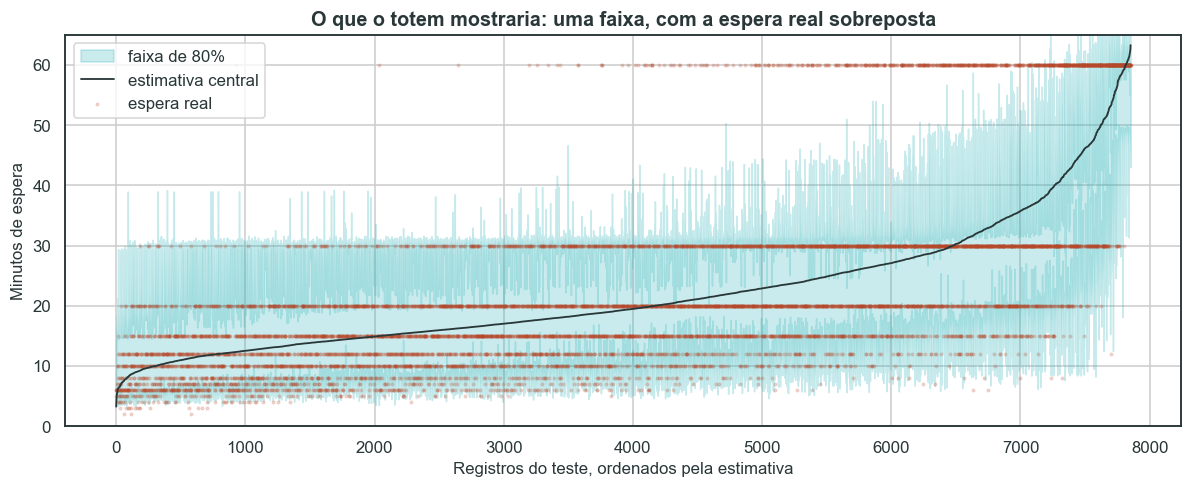

Como a informação chegaria ao cidadão:

   próxima passagem em ~14.6 min  (entre  8.0 e 30.0)   ·   real 12.0 min  →  dentro da faixa
   próxima passagem em ~23.7 min  (entre 16.0 e 32.8)   ·   real 15.0 min  →  FORA da faixa
   próxima passagem em ~14.1 min  (entre  7.0 e 30.5)   ·   real  8.0 min  →  dentro da faixa
   próxima passagem em ~23.1 min  (entre  8.8 e 30.7)   ·   real 30.0 min  →  dentro da faixa
   próxima passagem em ~23.8 min  (entre 18.0 e 29.7)   ·   real 20.0 min  →  dentro da faixa
   próxima passagem em ~31.9 min  (entre 16.4 e 51.1)   ·   real 30.0 min  →  dentro da faixa


In [27]:
baixo, alto = faixa(idx_teste, folga)
ordem_exibicao = np.argsort(pred_teste)

plt.figure(figsize=(11, 4.6))
plt.fill_between(range(len(ordem_exibicao)), baixo[ordem_exibicao], alto[ordem_exibicao],
                 color=AZUL, alpha=0.25, label="faixa de 80%")
plt.plot(pred_teste[ordem_exibicao], color=GRAFITE, lw=1.2, label="estimativa central")
plt.scatter(range(len(ordem_exibicao)), y_teste.values[ordem_exibicao],
            s=3, alpha=0.18, color=LARANJA, label="espera real")
plt.xlabel("Registros do teste, ordenados pela estimativa")
plt.ylabel("Minutos de espera")
plt.title("O que o totem mostraria: uma faixa, com a espera real sobreposta")
plt.legend(loc="upper left"); plt.ylim(0, 65)
plt.tight_layout(); plt.savefig(FIG / "11_faixa_conformal.png"); plt.show()

print("Como a informação chegaria ao cidadão:\n")
for i in np.random.RandomState(1).choice(len(idx_teste), 6, replace=False):
    real = y_teste.values[i]
    dentro = "dentro da faixa" if baixo[i] <= real <= alto[i] else "FORA da faixa"
    print(f"   próxima passagem em ~{pred_teste[i]:4.1f} min  "
          f"(entre {baixo[i]:4.1f} e {alto[i]:4.1f})   ·   real {real:4.1f} min  →  {dentro}")

---
## 10. Leitura do resultado para o cidadão

A tradução do modelo para a calçada: por período do dia, quanto o totem erraria ao anunciar a espera de uma linha sem dado publicado.

Desempenho por período do dia, no conjunto de teste:

                 Registros  Espera real (min)  Espera prevista (min)  Erro médio (min)
periodo                                                                               
madrugada              770               40.9              41.500000              11.1
pico_manha            1543               17.7              17.700001               7.0
entrepico_manha       1109               20.9              20.600000               7.7
almoco                1105               19.1              19.299999               6.6
entrepico_tarde        746               17.7              17.799999               6.6
pico_tarde            1501               19.8              19.900000               7.2
noite                 1080               25.4              25.600000               8.2


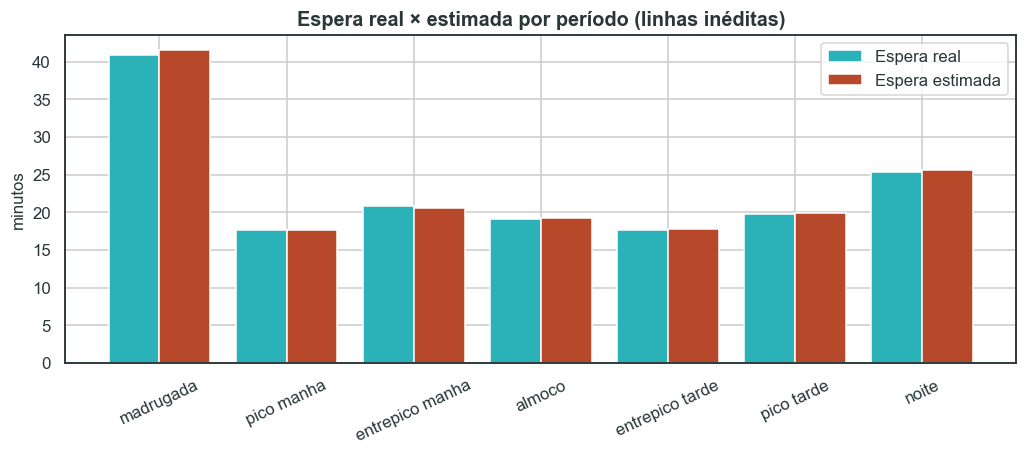

In [28]:
leitura = (pd.DataFrame({
        "periodo": dados.loc[idx_teste, "periodo"].values,
        "real": y_teste.values, "previsto": pred_teste})
    .assign(erro=lambda d: (d.real - d.previsto).abs())
    .groupby("periodo")
    .agg(registros=("real", "size"), espera_real=("real", "mean"),
         espera_prevista=("previsto", "mean"), erro_medio=("erro", "mean"))
    .round(1).loc[ordem])

leitura.columns = ["Registros", "Espera real (min)", "Espera prevista (min)", "Erro médio (min)"]
print("Desempenho por período do dia, no conjunto de teste:\n")
print(leitura.to_string())

plt.figure(figsize=(9.5, 4.3))
pos = np.arange(len(leitura))
plt.bar(pos - 0.2, leitura["Espera real (min)"], 0.4, label="Espera real", color=AZUL)
plt.bar(pos + 0.2, leitura["Espera prevista (min)"], 0.4, label="Espera estimada", color=LARANJA)
plt.xticks(pos, [p.replace("_", " ") for p in leitura.index], rotation=25)
plt.ylabel("minutos"); plt.title("Espera real × estimada por período (linhas inéditas)")
plt.legend(); plt.tight_layout(); plt.savefig(FIG / "07_leitura_cidadao.png"); plt.show()

**Leitura dos números.**

O modelo erra de 7 a 8 minutos em uma linha que nunca viu, contra cerca de 10 da mediana da cidade. Não é precisão para o totem anunciar *"faltam 4 minutos"* — essa informação continua vindo do dado publicado e da telemetria.

É precisão para o que ele se propõe: **identificar o regime de espera**. Distinguir cerca de 10 minutos de cerca de 40 altera a decisão de quem está na calçada — esperar, caminhar até outro ponto ou procurar outro modal.

E o acerto é melhor justamente onde a espera é maior e a informação vale mais: madrugada, noite e linhas noturnas.

---
## 11. Onde instalar os totens primeiro — KMeans + PCA

O modelo supervisionado responde *quanto se espera*. Resta a pergunta de implantação: **não é possível instalar 22 mil totens de uma vez — por onde começar?**

Aqui o problema é de agrupamento, não de previsão. Cada parada é descrita pela oferta que recebe, e paradas semelhantes são agrupadas com **KMeans**, usando **PCA** para reduzir a dimensão antes do agrupamento e para visualizar o resultado.

In [29]:
# Perfil de cada parada: quanta oferta recebe e quanto se espera nela
paradas_linhas = (stop_times[["trip_id", "stop_id"]]
    .merge(trips[["trip_id", "route_id"]], on="trip_id")
    .merge(dados[["route_id", "linha_noturna", "area_operacao",
                  "atende_metro", "atende_terminal"]].drop_duplicates("route_id"),
           on="route_id"))

espera_media_linha = dados.groupby("route_id")["headway_min"].mean().rename("espera_linha")
espera_pico = (dados[dados.periodo.isin(["pico_manha", "pico_tarde"])]
               .groupby("route_id")["headway_min"].mean().rename("espera_pico"))
paradas_linhas = paradas_linhas.join(espera_media_linha, on="route_id").join(espera_pico, on="route_id")

perfil = paradas_linhas.groupby("stop_id").agg(
    n_linhas=("route_id", "nunique"),
    espera_media=("espera_linha", "mean"),
    espera_pico=("espera_pico", "mean"),
    melhor_espera=("espera_linha", "min"),
    prop_noturnas=("linha_noturna", "mean"),
    prop_metro=("atende_metro", "mean"),
    prop_terminal=("atende_terminal", "mean"),
    n_areas=("area_operacao", "nunique"),
).join(stops.set_index("stop_id")[["stop_lat", "stop_lon", "stop_name"]])

perfil = perfil.dropna(subset=["stop_lat", "espera_media", "espera_pico"])
perfil["dist_centro_km"] = haversine(perfil.stop_lat, perfil.stop_lon, SE_LAT, SE_LON)

COLUNAS_AGRUPAMENTO = ["n_linhas", "espera_media", "espera_pico", "melhor_espera",
                       "prop_noturnas", "prop_metro", "prop_terminal",
                       "n_areas", "dist_centro_km"]
print(f"{len(perfil):,} paradas com perfil completo, descritas por {len(COLUNAS_AGRUPAMENTO)} atributos")
perfil[COLUNAS_AGRUPAMENTO].describe().round(2)

21,933 paradas com perfil completo, descritas por 9 atributos


,n_linhas,espera_media,espera_pico,melhor_espera,prop_noturnas,prop_metro,prop_terminal,n_areas,dist_centro_km
count,21933.00,21933.00,21933.00,21933.00,21933.00,21933.00,21933.00,21933.00,21933.00
mean,4.37,24.95,19.21,16.93,0.08,0.36,0.41,1.32,13.79
std,4.70,9.31,9.18,8.84,0.14,0.38,0.38,0.69,6.84
min,1.00,5.27,2.94,5.27,0.00,0.00,0.00,1.00,0.13
25%,1.00,18.14,13.06,11.37,0.00,0.00,0.00,1.00,8.59
50%,3.00,23.97,17.52,14.55,0.00,0.25,0.36,1.00,13.16
75%,5.00,30.39,23.53,19.62,0.12,0.67,0.67,1.00,18.55
max,41.00,60.00,60.00,60.00,0.86,1.00,1.00,8.00,42.34


PCA: 6 componentes retêm 93.1% da variância (de 9 atributos originais)


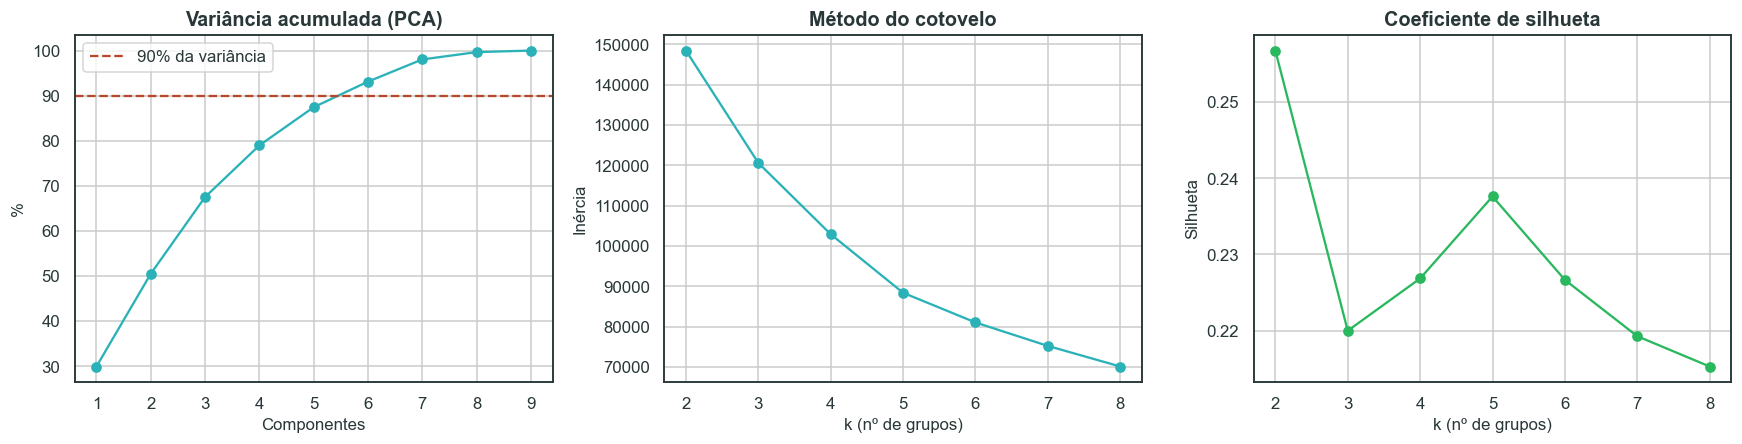

 k  inercia  silhueta
 2 148420.0     0.257
 3 120594.0     0.220
 4 102922.0     0.227
 5  88412.0     0.238
 6  81061.0     0.227
 7  75246.0     0.219
 8  70147.0     0.215


In [30]:
escalador = StandardScaler()
P = escalador.fit_transform(perfil[COLUNAS_AGRUPAMENTO])

pca_completo = PCA(random_state=SEMENTE).fit(P)
variancia = np.cumsum(pca_completo.explained_variance_ratio_)
n_comp = int(np.argmax(variancia >= 0.90) + 1)

pca = PCA(n_components=n_comp, random_state=SEMENTE)
P_reduzido = pca.fit_transform(P)
print(f"PCA: {n_comp} componentes retêm {variancia[n_comp-1]*100:.1f}% da variância "
      f"(de {len(COLUNAS_AGRUPAMENTO)} atributos originais)")

# Escolha de k: cotovelo + silhueta
inercias, silhuetas, ks = [], [], range(2, 9)
amostra = np.random.choice(len(P_reduzido), 5000, replace=False)
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10).fit(P_reduzido)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(P_reduzido[amostra], km.labels_[amostra]))

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.2))
eixos[0].plot(range(1, len(variancia) + 1), variancia * 100, marker="o", color=AZUL)
eixos[0].axhline(90, color=LARANJA, ls="--", label="90% da variância")
eixos[0].set(title="Variância acumulada (PCA)", xlabel="Componentes", ylabel="%"); eixos[0].legend()
eixos[1].plot(ks, inercias, marker="o", color=AZUL)
eixos[1].set(title="Método do cotovelo", xlabel="k (nº de grupos)", ylabel="Inércia")
eixos[2].plot(ks, silhuetas, marker="o", color=VERDE)
eixos[2].set(title="Coeficiente de silhueta", xlabel="k (nº de grupos)", ylabel="Silhueta")
plt.tight_layout(); plt.savefig(FIG / "08_escolha_k.png"); plt.show()

print(pd.DataFrame({"k": list(ks), "inercia": np.round(inercias), "silhueta": np.round(silhuetas, 3)}).to_string(index=False))

### Escolha do número de grupos

O cotovelo é suave e a silhueta é **modesta em todo k** (0,21 a 0,26), com máximo em k = 2. Não é defeito do método: as paradas de São Paulo formam um **contínuo**, não grupos separados.

Adotou-se **k = 4** por razão operacional — k = 2 apenas separaria "muita" de "pouca" oferta, o que não permite montar uma fila de instalação. Os grupos são faixas de um espectro, não fronteiras rígidas, e é assim que são tratados.

In [31]:
K = 4   # justificativa na célula de texto acima
kmeans = KMeans(n_clusters=K, random_state=SEMENTE, n_init=20)
perfil["grupo"] = kmeans.fit_predict(P_reduzido)

resumo = perfil.groupby("grupo")[COLUNAS_AGRUPAMENTO].mean().round(2)
resumo["paradas"] = perfil.groupby("grupo").size()
print("Perfil médio de cada grupo:\n")
print(resumo.to_string())

Perfil médio de cada grupo:

       n_linhas  espera_media  espera_pico  melhor_espera  prop_noturnas  prop_metro  prop_terminal  n_areas  dist_centro_km  paradas
grupo                                                                                                                                
0         11.57         26.38        20.64          11.84           0.11        0.36           0.46     2.32           10.22     3915
1          3.53         25.54        17.06          15.76           0.14        0.12           0.72     1.13           17.13     7156
2          2.49         18.69        14.50          14.41           0.03        0.61           0.10     1.10           12.80     8099
3          1.90         39.73        36.59          34.51           0.05        0.23           0.44     1.06           13.06     2763


In [32]:
# Nomear os grupos pelo PERFIL que cada um apresenta, e não pela ordem de espera.
# Cada regra identifica o grupo pelo atributo em que ele é extremo.
rotulos, prioridades = {}, {}
restantes = list(resumo.index)

def marcar(grupo, nome, prioridade):
    rotulos[grupo], prioridades[grupo] = nome, prioridade
    restantes.remove(grupo)

# 1) Parada isolada: a maior espera no pico, com a menor oferta de linhas
marcar(resumo.loc[restantes, "espera_pico"].idxmax(),
       "Parada isolada de longa espera", "1 — equidade (PRIORIDADE MÁXIMA)")

# 2) Hub de integração: muitas linhas e mais de uma área de operação na mesma parada
marcar(resumo.loc[restantes, "n_linhas"].idxmax(),
       "Hub de integração", "2 — alcance")

# 3) Parada já integrada ao metrô: a maior proporção de linhas que servem o metrô
marcar(resumo.loc[restantes, "prop_metro"].idxmax(),
       "Parada integrada ao metrô", "4 — já bem servida")

# 4) O que sobra é o corredor comum de bairro
for grupo in list(restantes):
    marcar(grupo, "Corredor de bairro", "3 — expansão")

perfil["nome_grupo"] = perfil["grupo"].map(rotulos)
perfil["prioridade_totem"] = perfil["grupo"].map(prioridades)

painel = resumo.copy()
painel.index = [rotulos[g] for g in painel.index]
painel = painel[["paradas", "n_linhas", "n_areas", "espera_media", "espera_pico",
                 "prop_metro", "dist_centro_km"]]
painel.columns = ["Paradas", "Linhas por parada", "Áreas atendidas", "Espera média (min)",
                  "Espera no pico (min)", "% linhas c/ metrô", "Dist. do centro (km)"]
painel["Prioridade"] = [prioridades[g] for g in resumo.index]
print(painel.sort_values("Prioridade").to_string())

                                Paradas  Linhas por parada  Áreas atendidas  Espera média (min)  Espera no pico (min)  % linhas c/ metrô  Dist. do centro (km)                        Prioridade
Parada isolada de longa espera     2763               1.90             1.06               39.73                 36.59               0.23                 13.06  1 — equidade (PRIORIDADE MÁXIMA)
Hub de integração                  3915              11.57             2.32               26.38                 20.64               0.36                 10.22                       2 — alcance
Corredor de bairro                 7156               3.53             1.13               25.54                 17.06               0.12                 17.13                      3 — expansão
Parada integrada ao metrô          8099               2.49             1.10               18.69                 14.50               0.61                 12.80                4 — já bem servida


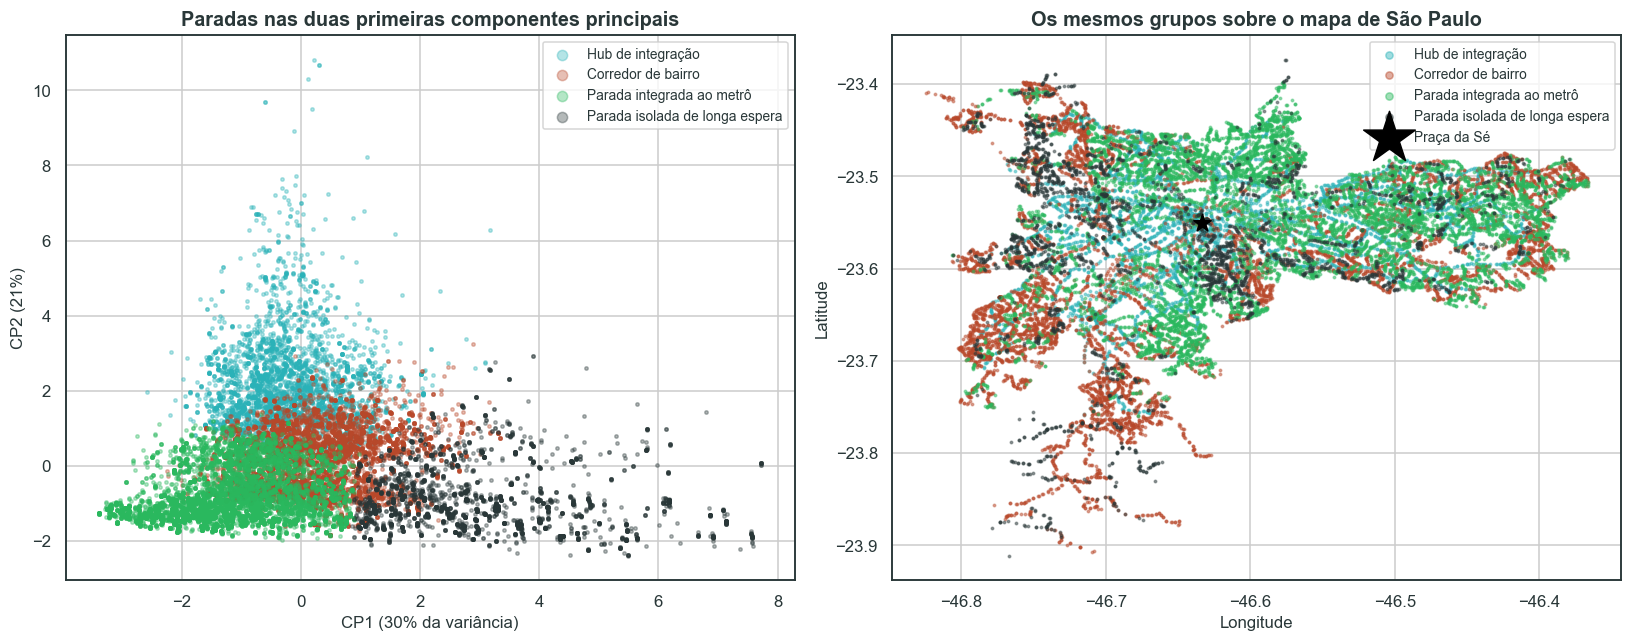

In [33]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 6))
cores = {g: PALETA[i] for i, g in enumerate(sorted(perfil.grupo.unique()))}

for g in sorted(perfil.grupo.unique()):
    sub = perfil[perfil.grupo == g]
    eixos[0].scatter(P_reduzido[perfil.grupo.values == g, 0],
                     P_reduzido[perfil.grupo.values == g, 1],
                     s=5, alpha=0.35, color=cores[g], label=rotulos[g])
eixos[0].set(title="Paradas nas duas primeiras componentes principais",
             xlabel=f"CP1 ({pca.explained_variance_ratio_[0]*100:.0f}% da variância)",
             ylabel=f"CP2 ({pca.explained_variance_ratio_[1]*100:.0f}%)")
eixos[0].legend(markerscale=3, fontsize=9)

for g in sorted(perfil.grupo.unique()):
    sub = perfil[perfil.grupo == g]
    eixos[1].scatter(sub.stop_lon, sub.stop_lat, s=2.5, alpha=0.45,
                     color=cores[g], label=rotulos[g])
eixos[1].scatter([SE_LON], [SE_LAT], s=140, marker="*", color="black",
                 zorder=5, label="Praça da Sé")
eixos[1].set(title="Os mesmos grupos sobre o mapa de São Paulo",
             xlabel="Longitude", ylabel="Latitude")
eixos[1].legend(markerscale=3, fontsize=9)

plt.tight_layout(); plt.savefig(FIG / "09_agrupamento_paradas.png"); plt.show()

O que separa os grupos **não é a distância do centro** — os quatro ficam entre 10 e 17 km —, mas a **oferta**: o hub concentra cerca de 11 linhas por parada e atende mais de uma área, enquanto a parada isolada tem menos de 2 linhas e quase 37 minutos de espera no pico. Duas paradas no mesmo bairro podem estar em grupos opostos.

Daí saem duas filas, e não uma:

- **Prioridade 1 — equidade.** As paradas isoladas: espera superior a meia hora, sem informação alguma e frequentemente com uma única linha como alternativa.
- **Prioridade 2 — alcance.** Os hubs: a espera é menor, mas cada totem atende muito mais gente e resolve outro problema — **qual** das onze linhas tomar.

Ressalva: o agrupamento mede a oferta, não quantas pessoas usam cada parada. A ordem entre as duas filas é uma escolha de política, não um resultado do dado.

In [34]:
prioridade = (perfil.sort_values(["prioridade_totem", "espera_pico"], ascending=[True, False])
              [["stop_name", "stop_lat", "stop_lon", "n_linhas", "espera_media",
                "espera_pico", "prop_noturnas", "dist_centro_km",
                "nome_grupo", "prioridade_totem"]].round(3))
prioridade.index.name = "stop_id"
prioridade.to_csv(ART / "prioridade_totens.csv", encoding="utf-8")

print(f"{len(prioridade):,} paradas classificadas → artefatos/prioridade_totens.csv")
print(f"\nParadas de prioridade máxima: {(perfil.prioridade_totem.str.startswith('1')).sum():,}")
print("\nAs 10 primeiras paradas da fila de instalação:\n")
print(prioridade.head(10)[["stop_name", "n_linhas", "espera_pico", "nome_grupo"]].to_string())

21,933 paradas classificadas → artefatos/prioridade_totens.csv

Paradas de prioridade máxima: 2,763

As 10 primeiras paradas da fila de instalação:

                                   stop_name  n_linhas  espera_pico                      nome_grupo
stop_id                                                                                            
170011305                     R. Jorge Amado         2         60.0  Parada isolada de longa espera
300009316  Av. Paulo Guilguer Reimberg, 9941         1         60.0  Parada isolada de longa espera
3014968               Av. Kayo Okamoto, 1787         1         60.0  Parada isolada de longa espera
3015030                 R. Tadao Inoue, 2245         1         60.0  Parada isolada de longa espera
3015031                 R. Tadao Inoue, 2240         1         60.0  Parada isolada de longa espera
3015038                    R. Tadao Inoue, 8         1         60.0  Parada isolada de longa espera
3015039                    R. Tadao Inoue, 8       

---
## 12. Artefatos para o restante da CitizenTech

O S.B.P. é um ecossistema: o que esta análise produz precisa chegar ao totem, ao aplicativo e ao site. São exportados três artefatos consumidos pelo backend:

1. **`modelo_espera.joblib`** — o modelo treinado, para estimar a espera de linhas sem dado publicado;
2. **`espera_por_linha_hora.csv`** — a espera estimada por linha e hora, pronta para alimentar o painel do totem;
3. **`prioridade_totens.csv`** — a fila de instalação dos totens.

In [35]:
import joblib

joblib.dump({"modelo": modelo_final,
             "modelo_faixa_inferior": modelo_inferior,
             "modelo_faixa_superior": modelo_superior,
             "folga_conformal_min": float(folga),
             "cobertura_da_faixa": 1 - ALFA,
             "atributos_numericos": ATRIBUTOS_NUMERICOS,
             "atributos_categoricos": ATRIBUTOS_CATEGORICOS,
             "mae_teste_min": float(mean_absolute_error(y_teste, pred_teste)),
             "r2_teste": float(r2_score(y_teste, pred_teste)),
             "vies_teste_min": float((y_teste - pred_teste).mean()),
             "treinado_em": "GTFS SPTrans, 2.236 viagens, 39.777 registros"},
            ART / "modelo_espera.joblib")

# O painel leva a estimativa central E a faixa, para que o backend possa
# exibir "entre X e Y minutos" quando a origem do dado for o modelo.
faixa_baixo, faixa_alto = faixa(np.arange(len(X)), folga)
painel_totem = (dados.assign(espera_estimada=modelo_final.predict(X),
                             faixa_min=faixa_baixo, faixa_max=faixa_alto)
    .groupby(["route_short_name", "route_long_name", "hora"])
    .agg(espera_publicada_min=("headway_min", "mean"),
         espera_estimada_min=("espera_estimada", "mean"),
         faixa_min=("faixa_min", "mean"),
         faixa_max=("faixa_max", "mean"))
    .round(1).reset_index()
    .rename(columns={"route_short_name": "linha", "route_long_name": "nome_linha"}))
painel_totem.to_csv(ART / "espera_por_linha_hora.csv", index=False, encoding="utf-8")

print("Artefatos gravados em artefatos/:")
for arquivo in sorted(ART.iterdir()):
    print(f"  {arquivo.name:<32} {arquivo.stat().st_size/1024:>8.1f} KB")

print("\nAmostra do painel do totem:\n")
print(painel_totem[painel_totem.linha == painel_totem.linha.iloc[0]].head(6).to_string(index=False))

Artefatos gravados em artefatos/:
  espera_por_linha_hora.csv          1425.8 KB
  modelo_espera.joblib               6311.9 KB
  prioridade_totens.csv              2648.3 KB

Amostra do painel do totem:

  linha                          nome_linha  hora  espera_publicada_min  espera_estimada_min  faixa_min  faixa_max
1012-10 Term. Jd. Britania - Jd. Monte Belo     0                  20.0            30.200001       18.5       54.8
1012-10 Term. Jd. Britania - Jd. Monte Belo     1                  60.0            49.400002       23.8       62.7
1012-10 Term. Jd. Britania - Jd. Monte Belo     3                  15.0            29.299999       14.0       58.0
1012-10 Term. Jd. Britania - Jd. Monte Belo     4                  10.0            11.000000        9.2       41.6
1012-10 Term. Jd. Britania - Jd. Monte Belo     5                   7.0             9.400000        5.9       21.4
1012-10 Term. Jd. Britania - Jd. Monte Belo     6                   8.0             8.000000        5.6  

---
## 13. Conclusão

**A pergunta.** É possível estimar quanto o cidadão espera no ponto a partir apenas do desenho da linha e da geografia, sem conhecer a linha?

**A resposta.** Em parte, e de forma útil. O modelo erra de 7 a 8 minutos em uma linha que nunca viu, contra cerca de 10 da mediana da cidade, e entrega uma faixa de 80% com cobertura verificada. Não é precisão para anunciar *"faltam 4 minutos"* — é precisão para distinguir uma espera de 10 minutos de uma de 40, que é a informação ausente hoje em quase toda parada.

**O limite.** Mais da metade da variância está no patamar de cada linha, e esse patamar não é inferível da rede: a correlação com as linhas que dividem suas paradas é praticamente zero, e o melhor atributo novo construído contribuiu pouco. Não se trata de ajuste insuficiente nem de falta de um modelo mais sofisticado, mas de uma variável ausente no dado público — a demanda e a frota alocada àquela linha. O GTFS, além disso, descreve a oferta **programada**, não a realizada.

**O que mudou ao longo do trabalho.** A densidade urbana foi o único atributo novo com ganho real. A troca da função-objetivo eliminou um viés de 2 minutos que levava o modelo a subestimar a espera. A predição conformal substituiu o número solto por uma faixa calibrada. E o bloqueio de uma região inteira mostrou que a aplicação a uma cidade sem dado algum é mais frágil do que parecia.

**A decisão mais importante foi metodológica.** A divisão aleatória daria um resultado melhor e **falso**. Medir de forma honesta é o que impede o S.B.P. de anunciar na calçada uma precisão que não cumpre.

**Para o cidadão.** Quem chega ao ponto passa a ter uma faixa confiável em vez de nenhuma informação, inclusive sem conexão. E o agrupamento define onde o totem deve chegar primeiro: nas paradas isoladas de longa espera, e não nas já servidas pelo metrô.

**O próximo dado**, em ordem de valor: a **API Olho Vivo** da SPTrans, que muda o alvo de espera programada para realizada; o **Censo 2022 do IBGE**, demanda por setor censitário cruzada com a coordenada da parada; e a **bilhetagem por linha**, se publicada — a medida direta da variável ausente.